## **다중 LLM 활용 + ReAct 에이전트 (LangGraph 버전)**
- 순차 / 병렬 Multi-LLM + GPT 종합 구조, 그리고 ReAct(생각 → 행동 → 관찰) 루프
- exam4(basicedu) 는 **SDK 직접 호출**, exam5(fwedu) 는 **LangChain(체인)** 이었습니다.
- 이 노트북(exam12)에서는 **흐름 제어가 필요한 부분을 LangGraph 로** 다시 만듭니다. \
  모델 호출(**`프롬프트 | 모델 | 파서`**)은 그대로 LangChain 을 쓰고, **"누가 언제 실행되는가"** 를 그래프가 맡습니다.

| 사용 버전 (2026-10 기준) | 패키지 |
|---|---|
| `langgraph` 1.2.x | `StateGraph`, `START/END`, `ToolNode`, `tools_condition`, `InMemorySaver` |
| `langchain` 1.4.x / `langchain-core` 1.6.x | 메시지, `@tool`, 프롬프트 템플릿, 출력 파서 |
| `langchain-openai` 1.7.x | `ChatOpenAI` |
| `langchain-google-genai` 4.4.x | `ChatGoogleGenerativeAI` |
| `langchain-ollama` 1.1.x | `ChatOllama` |

> **한눈에 보기**
> - 10/20 exam5(LangChain)의 다중 LLM 병렬 종합·순차 파이프라인·ReAct를 LangGraph `StateGraph`로 다시 구현
> - 병렬: START → 노드 3개(fan-out), `add_edge([...], "synthesize")`(fan-in). 순차: 리뷰어가 Fail이면 조건부 엣지로 개발자에게 되돌림(`MAX_REVISIONS`)
> - ReAct = `agent ⇄ tools` 순환. 도구 실패 처리 3가지: 오류를 모델에 전달(`handle_tool_errors=True`) / 실패 횟수 라우팅 / `RetryPolicy`(예외를 노드 밖으로)
> - 재사용 가능한 `build_react_graph()` + 체크포인터 대화 기억, `create_agent` 한 줄과 비교
> - 정리 문서: [다중LLM과ReAct_LangGraph.md](다중LLM과ReAct_LangGraph.md) · 강의 슬라이드 이미지 포함, 📝 정리 셀은 직접 정리

### 전체 흐름 한눈에 보기

### LangGraph 란?

**LangGraph 는 LLM 애플리케이션을 "그래프(노드 + 화살표)"로 설계하고 실행하는 프레임워크입니다.**
- 체인(Chain) : 정해진 순서에 따라 작업을 연결하고 실행하는 데 적합합니다.
- 그래프(Graph) : 노드(Node)와 엣지(Edge)를 통해 작업 간의 연결 관계와 실행 조건을 표현합니다.
- 중요한 차이 : 체인도 조건문이나 반복문을 조합해 복잡한 작업을 수행할 수 있으며 그래프는 이러한 흐름을 구조적으로 표현하고 관리하기에 더 적합합니다.

| 용어 | 비유 | 코드에서는 |
|---|---|---|
| **State (상태)** | 모두가 함께 쓰는 **공유 화이트보드** | `TypedDict`\ `MessagesState` <br> 질문, 답변, 메시지 목록 등을 담는 딕셔너리 |
| **Node (노드)** | 화이트보드를 읽고 일부를 고쳐 쓰는 **직원** | <span style="color:red">**def node(state) -> {바꿀 키: 값}**</span> 파이썬 함수 |
| **Edge (엣지)** | 다음에 누가 일할지 알려주는 **화살표** | <span style="color:red">**add_edge(A, B)**</span> |
| **Conditional Edge** | 상황을 보고 길을 고르는 **갈림길** | <span style="color:red">**add_conditional_edges(A, 라우팅함수)**</span> |
| **Reducer (리듀서)** | 같은 칸에 여러 직원이 쓸 때의 **합치기 규칙** | <span style="color:red">**Annotated[list, add_messages]**</span>(덧붙이기), <br> 없으면 **덮어쓰기** |
| **compile()** | 설계도를 **실행 가능한 앱**으로 확정 | `graph = builder.compile()` |
| **Checkpointer** | 화이트보드를 **사진으로 저장** → 기억·재개 | `InMemorySaver()` + `thread_id` |

- 노드는 **상태 전체를 받아서, 바꾸고 싶은 키만 딕셔너리로 반환**합니다. (나머지는 그대로 유지)
- 그래프는 **슈퍼스텝** 단위로 실행됩니다. 같은 슈퍼스텝의 노드들은 **동시에** 실행되고, 모두 끝나면 다음 슈퍼스텝으로 넘어갑니다.

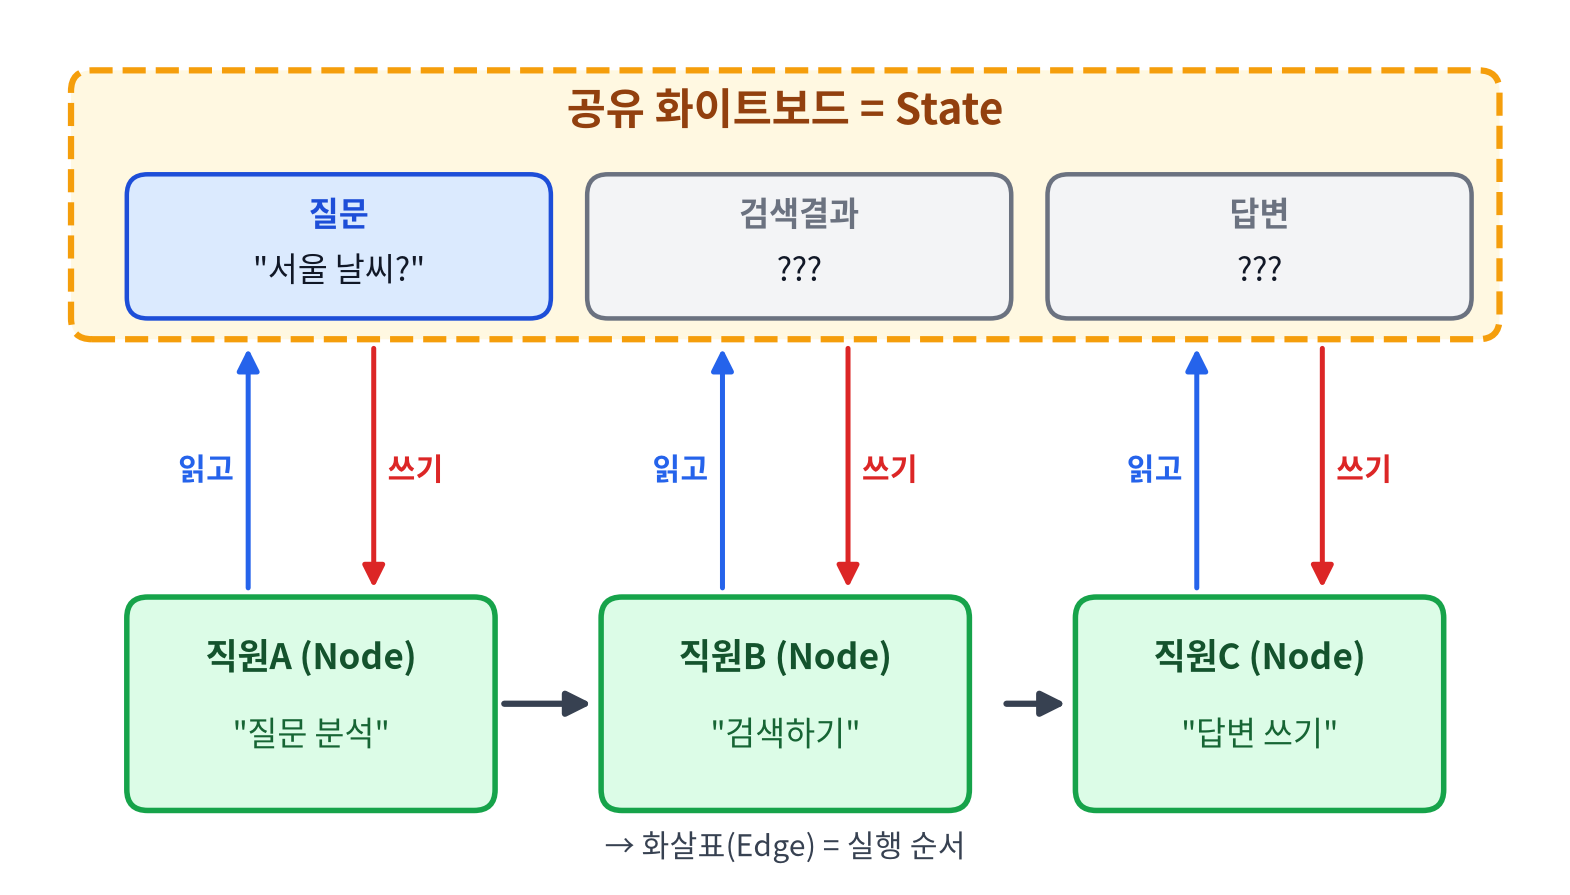

### exam5(LangChain) → exam12(LangGraph) 로 달라지는 점

| 구분 | exam5 (LangChain) | exam12 (LangGraph) |
|---|---|---|
| 3개 모델 병렬 호출 | `RunnableParallel` / `assign` | **병렬 노드 3개 + fan-in 엣지** — 결과는 State 의 각 칸에 저장 |
| 순차 파이프라인 | `assign(...)` 을 `\|` 로 연결 | **노드 3개를 엣지로 연결**, 결과는 State 로 전달 |
| 리뷰가 Fail 이면? | RunnableBranch나 일반 Python 로직 등을 활용해 조건에 따른 처리를 구현 | 조건부 엣지와 순환 경로를 그래프에 명시해 리뷰 실패 시 재검토하거나 개발자에게 검토를 요청하는 흐름을 구조적으로 관리하기 쉬움 |
| ReAct 루프 (소스 1) | `while` 루프 직접 작성 | **agent 노드 + tools 노드 + 조건부 엣지** 로 루프를 그래프화 |
| ReAct 에이전트 (소스 2, 3) | `create_agent(...)`는 내부 구현을 직접 조립하지 않는 고수준 API | `StateGraph` 로 **직접 조립** (`ToolNode`, `tools_condition`) |
| 대화 기억 | 별도 기록 관리 설정 | **체크포인터와 thread_id** 를 활용한 실행 상태 관리 |
| 구조 확인 | `get_graph()` (Runnable 연결 구조) | `get_graph()` (노드·엣지와 제어 흐름을 명시적으로 표현한 그래프) |

<br>

#### LangChain
- 작업을 쉽게 연결하고 모델·도구를 활용하는 데 초점
- 입력 → 프롬프트 → 모델 → 출력
- 정형화된 파이프라인과 고수준 에이전트 API를 빠르게 구성하기 좋습니다.


#### LangGraph
- 복잡한 실행 흐름과 상태를 제어하는 데 초점
- 입력 → 판단 → 도구 실행 → 결과 평가 → 재실행 또는 종료
- 분기, 반복, 사람의 승인, 상태 저장 및 중단 후 재개가 필요한 워크플로를 명시적으로 설계하기 좋습니다.

#### 준비 사항

**1) 패키지 설치** (버전을 고정하면 실습 환경이 항상 같아집니다)
```
pip install "langgraph==1.2.16" "langchain==1.4.6" "langchain-openai==1.7.2" "langchain-google-genai==4.4.2" "langchain-ollama==1.1.0" 
```

**2) API 키** — 환경변수 또는 프로젝트 폴더의 `.env` 파일에 넣어 둡니다.
```
OPENAI_API_KEY=sk-...
GEMINI_API_KEY=...        # GOOGLE_API_KEY 라는 이름도 인식됩니다
```

**3) Ollama (로컬 모델)**
```
ollama pull exaone4.0          # 가벼운 PC 라면 exaone4.0:1.2b
```

In [1]:
import os
import time
from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_ollama import ChatOllama

# 3개의 모델 객체 — 클래스만 다를 뿐, 사용법(invoke)은 모두 똑같습니다. (모델 쪽은 LangChain 그대로)
# 1. 3개의 모델 객체 생성
gpt = ChatOpenAI(model="gpt-4o-mini")
# Google Gemini (사용 가능한 모델명 지정)
gemini = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")
# 로컬 Ollama (로컬에 설치된 정확한 모델명/태그 지정)
OLLAMA_MODEL = "exaone4.0" 
ollama4 = ChatOllama(model=OLLAMA_MODEL, base_url="http://localhost:11434")
ollama3 = ChatOllama(model="exaone3.5", base_url="http://localhost:11434")


Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [2]:

# 2. 순회 실행 및 테스트
for name, llm in [("gpt", gpt), ("gemini", gemini), ("ollama", ollama3)]:
    try:
        # 💡 핵심 수정: .text -> .content 로 변경
        response = llm.invoke("한 단어로 인사해줘")
        text_output = response.text if hasattr(response, "text") else str(response.content)
        print(f"{name} → {text_output.strip()}")
    except Exception as e:
        print(f"{name} → 연결 실패: {e}")

gpt → 안녕하세요!
gemini → 안녕!
ollama → 안녕하세요!


### 노드 안에서 쓸 체인 만들기 (LangChain 부분은 그대로)

그래프의 **노드 = 파이썬 함수**이고, 그 안에서 모델을 호출합니다. 모델 호출 부분은 exam5와 같은 `프롬프트 | 모델 | 파서` 체인을 그대로 재사용합니다.
- 역할 분담: **LangChain = "무엇을 물을까 / 누구에게 물을까"**, \
                **LangGraph = "어떤 순서로 / 병렬로 / 반복해서 실행할까"**
- `safe()` 는 원본의 `try/except` 와 같은 역할로, 한 모델이 실패해도 그래프 전체가 멈추지 않게 해줍니다.

In [3]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda

parser = StrOutputParser()


def build_chain(llm, system: str | None = None):
    """프롬프트 | 모델 | 파서 로 이루어진 '질문 → 답변 문자열' 체인을 만든다."""
    messages = []
    if system:
        messages.append(("system", system))
    messages.append(("human", "{question}"))
    return ChatPromptTemplate.from_messages(messages) | llm | parser


def safe(chain, name: str):
    """한 모델이 실패해도 전체 흐름이 멈추지 않게 한다. (원본의 try/except)"""
    def _run(inputs, config):
        try:
            return chain.invoke(inputs, config)
        except Exception as e:
            return f"{name} 에러 (키/모델/서버 확인 필요): {e}"
    return RunnableLambda(_run)


ask_gpt    = safe(build_chain(gpt, "당신은 분석적이고 객관적인 IT 전문가입니다."), "OpenAI")
ask_gemini = safe(build_chain(gemini), "Gemini")
ask_ollama = safe(build_chain(ollama3), "Ollama")

### 1. 병렬 Multi-LLM + 종합 → `StateGraph`

**설계도** — State 에는 5개의 칸이 있고, 각 노드는 **자기 칸 하나만** 채웁니다.

| 노드 | 읽는 칸 | 쓰는 칸 |
|---|---|---|
| `ask_gpt` | question | gpt_answer |
| `ask_gemini` | question | gemini_answer |
| `ask_ollama` | question | ollama_answer |
| `synthesize` | question + 3개 답변 | report |

**병렬은 어떻게 표현할까?** — `START` 에서 3개 노드로 엣지를 3개 뻗으면, 세 노드가 **같은 슈퍼스텝에서 동시에** 실행됩니다.
(exam4(basicedu) 의 `ThreadPoolExecutor`, exam5(fwedu) 의 `RunnableParallel` 에 해당)

**합치기(fan-in)** — `add_edge(["ask_gpt", "ask_gemini", "ask_ollama"], "synthesize")` 처럼 **리스트**로 주면 3개가 **모두 끝난 뒤에** `synthesize` 가 한 번만 실행됩니다.
> ⚠️ 엣지를 `add_edge("ask_gpt","synthesize")` 처럼 따로따로 3개 만들면 "하나 끝날 때마다" 실행될 수 있습니다. 모두 기다리려면 반드시 리스트 형태를 사용합니다.

**리듀서가 필요 없는 이유** — 각 노드가 서로 다른 칸에 쓰기 때문에 충돌이 없습니다. 같은 칸에 동시에 쓰는 경우에만 `Annotated[list, operator.add]` 같은 리듀서가 필요합니다.

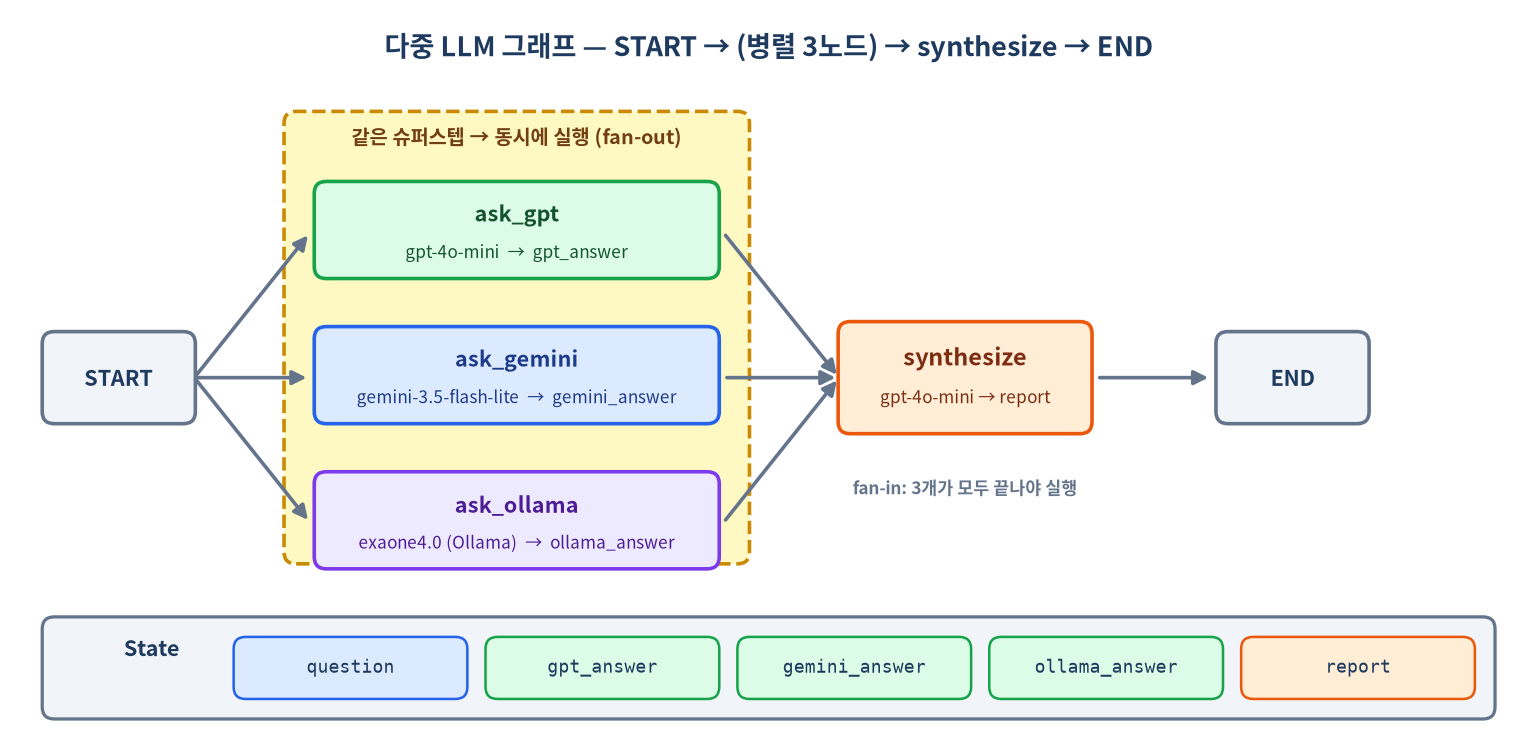

In [4]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


# ------------------------------------------------------------
# 1) State: 그래프 전체가 공유하는 화이트보드
# ------------------------------------------------------------
class MultiLLMState(TypedDict, total=False):      # total=False: 처음엔 일부 칸이 비어 있어도 OK
    question: str
    gpt_answer: str
    gemini_answer: str
    ollama_answer: str
    report: str


# ------------------------------------------------------------
# 2) Node: state 를 읽고 → 자기 칸만 dict 로 반환
# ------------------------------------------------------------
def make_ask_node(chain, answer_key: str):
    """같은 모양의 '질문하는 노드'를 모델별로 찍어내는 공장 함수."""
    def node(state: MultiLLMState):
        return {answer_key: chain.invoke({"question": state["question"]})}
    return node


# 종합 프롬프트 (exam11 과 동일)
synthesis_prompt = ChatPromptTemplate.from_messages([
    ("system", "당신은 수석 아키텍트이자 마스터 멘토입니다."),
    ("human", """아래는 동일한 질문에 대해 3개의 서로 다른 AI 모델(GPT, Gemini, 오픈소스 모델)이 내놓은 답변입니다.

[질문]
{question}

---
[AI 1: GPT의 의견]
{gpt_answer}

---
[AI 2: Gemini의 의견]
{gemini_answer}

---
[AI 3: 오픈소스 모델의 의견]
{ollama_answer}
---

위 3가지 시각을 종합 분석하여, 공통적인 핵심 권장 사항을 추려내고,
각 AI의 답변 스타일 차이점을 가볍게 평가하는 '최종 종합 가이드 리포트'를 깔끔한 마크다운 양식으로 작성해 주세요."""),
])
synthesis_chain = synthesis_prompt | gpt | parser     # 종합은 가장 신뢰하는 gpt-4o-mini 가 담당


def synthesize(state: MultiLLMState):
    # state 안에 question / gpt_answer / gemini_answer / ollama_answer 가 이미 들어 있으므로 그대로 프롬프트에 전달
    return {"report": synthesis_chain.invoke(state)}


# ------------------------------------------------------------
# 3) Graph: 노드 등록 → 엣지 연결 → compile
# ------------------------------------------------------------
builder = StateGraph(MultiLLMState)

builder.add_node("ask_gpt", make_ask_node(ask_gpt, "gpt_answer"))
builder.add_node("ask_gemini", make_ask_node(ask_gemini, "gemini_answer"))
builder.add_node("ask_ollama", make_ask_node(ask_ollama, "ollama_answer"))
builder.add_node("synthesize", synthesize)

# START → 3개 노드 (fan-out: 동시에 시작)
builder.add_edge(START, "ask_gpt")
builder.add_edge(START, "ask_gemini")
builder.add_edge(START, "ask_ollama")

# 3개 노드 → synthesize (fan-in: 리스트로 주면 '모두 끝난 뒤' 실행)
builder.add_edge(["ask_gpt", "ask_gemini", "ask_ollama"], "synthesize")
builder.add_edge("synthesize", END)

multi_llm_graph = builder.compile()

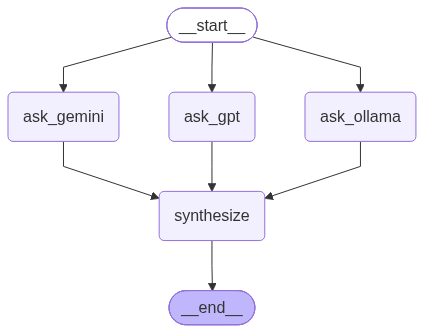

In [5]:
multi_llm_graph

In [6]:
from IPython.display import Markdown, display

user_question = "초보 개발자의 첫 웹 백엔드 스택으로 Python FastAPI와 Java Spring Boot 중 무엇을 더 추천하나요?"

print(f"❓ 공동 질문: '{user_question}'\n")
print("==============================================")
print("🔄 1단계: 3개의 다중 LLM에게 동시에 의견 묻는 중...")
print("==============================================\n")

labels = {
    "ask_gpt": "🤖 [OpenAI gpt-4o-mini 답변 완료]",
    "ask_gemini": "♊ [Google gemini-3.5-flash-lite 답변 완료]",
    "ask_ollama": "🦙 [Ollama 로컬 모델 답변 완료]",
}

state, start = {}, time.perf_counter()

# stream_mode="updates": 노드가 하나 끝날 때마다 "그 노드가 쓴 내용"만 알려준다.
# → 병렬로 실행되므로 '먼저 끝난 모델 순서대로' 출력됩니다. (원본은 GPT→Gemini→Ollama 순서로 기다렸음)
for update in multi_llm_graph.stream({"question": user_question}, stream_mode="updates"):
    for node, written in update.items():
        state.update(written)
        if node in labels:
            print(f"{labels[node]}  ({time.perf_counter() - start:.1f}초)\n")
        elif node == "synthesize":
            print("==============================================")
            print("🔄 2단계: 수집된 의견들을 종합 요약 완료 (by gpt-4o-mini)")
            print("==============================================\n")

print("✨ [최종 다중 LLM 취합 리포트] ✨\n")
display(Markdown(state["report"]))
# state["gpt_answer"], state["gemini_answer"], state["ollama_answer"] 도 그대로 남아 있습니다.

❓ 공동 질문: '초보 개발자의 첫 웹 백엔드 스택으로 Python FastAPI와 Java Spring Boot 중 무엇을 더 추천하나요?'

🔄 1단계: 3개의 다중 LLM에게 동시에 의견 묻는 중...

♊ [Google gemini-3.5-flash-lite 답변 완료]  (7.8초)

🤖 [OpenAI gpt-4o-mini 답변 완료]  (7.8초)

🦙 [Ollama 로컬 모델 답변 완료]  (51.4초)

🔄 2단계: 수집된 의견들을 종합 요약 완료 (by gpt-4o-mini)

✨ [최종 다중 LLM 취합 리포트] ✨



# 최종 종합 가이드 리포트: Python FastAPI vs. Java Spring Boot

## 공통적인 핵심 권장 사항

- **초보자에게는 Python FastAPI 추천**
  - **직관적인 문법**: Python의 간결한 문법 덕분에 초보자에게 더 친숙함.
  - **빠른 개발과 결과 확인**: 웹 서버 구축 및 API 테스트가 신속하게 가능.*
  - **자동 문서화**: FastAPI는 Swagger UI를 통해 별도의 도구 없이도 API 문서를 생성.
  - **커뮤니티 지원**: 큰 커뮤니티와 문서 지원 덕분에 학습과 문제 해결이 용이함.

- **Java Spring Boot의 장점**
  - **기업 표준**: 많은 기업에서 선호하여 취업에 유리할 수 있음.
  - **풍부한 기능**: 엔터프라이즈급 애플리케이션을 구축할 수 있는 다양한 기능 제공.
  - **높은 성능과 안정성**: 대규모 시스템에 적합한 안정성 제공.

- **학습 로드맵 제안**:
  1. FastAPI로 기본 개발 이해.
  2. 컴퓨터 과학 기초 지식 확립 (데이터베이스, 네트워크 등).
  3. Spring Boot로 확장하여 취업 준비.

## 각 AI의 답변 스타일 평가

### **AI 1: GPT의 의견**
- **스타일**: 균형 잡힌 분석과 포괄적인 정보 제공.
- **장점**: 명확한 장단점 정리, 추천 사유가 세분화되어 있음.
- **감상**: 초보자의 목표에 따라 다양한 선택지를 제시, 유연한 접근법을 강조.

### **AI 2: Gemini의 의견**
- **스타일**: 초보자 중심의 접근과 동기 부여 강조.
- **장점**: 개별적이며 구체적인 단계별 학습 로드맵 제공.
- **감상**: FastAPI의 흥미 유도 요소를 잘 파악하고 강조하며, Sinatra/UI와 같은 구체적인 기능을 언급.

### **AI 3: 오픈소스 모델의 의견**
- **스타일**: 간결하고 직설적인 접근.
- **장점**: FastAPI의 현대적인 기능을 간단하고 명료하게 설명.
- **감상**: 기술적 요구에 따라 선택하라는 점을 강조하며, 유연한 선택을 권장.

## 결론
초보 개발자가 조건에 맞는 웹 백엔드 스택을 선택할 때, 현재의 트렌드와 개인의 학습 스타일에 따라 **Python FastAPI**로의 접근이 더욱 바람직할 수 있으며, 이후 **Java Spring Boot**로 확장하는 경로가 추천됩니다. 각 AI의 답변은 상황에 따라 유용한 인사이트를 제공하며, 선택하는 데 있어 개인적인 선호도와 목표에 따라 조정할 수 있습니다.

**📝 정리** — 세 노드가 같은 슈퍼스텝에서 동시에 실행됐다: gemini 7.8초, gpt 7.8초, Ollama(exaone3.5) 51.4초. 전체 시간은 가장 느린 노드에 맞춰진다. 내 PC의 Ollama는 GPU 없이 CPU로 돈다.

<hr style="height:5px; background:linear-gradient(to right, red, green)">

**실행 방법 3가지** (`compile()` 된 그래프는 LangChain 의 Runnable 이라서 사용법이 같습니다)

| 메서드 | 결과 |
|---|---|
| `graph.invoke(입력)` | 모두 끝난 뒤 **최종 State** 한 번에 반환 |
| `graph.stream(입력, stream_mode="updates")` | **노드가 끝날 때마다** 그 노드가 쓴 내용 (진행 상황 출력에 적합) |
| `graph.stream(입력, stream_mode="values")` | 슈퍼스텝마다 **State 전체** 스냅샷 |

비동기는 `await graph.ainvoke(...)` / `async for ... in graph.astream(...)` 입니다.

**이 소스의 노드 워크플로우**를 그림으로 확인합니다. `get_graph()` 는 컴파일된 그래프의 노드/엣지 구조를 돌려주고,
`draw_mermaid_png()` 가 이를 이미지로 만듭니다. (인터넷이 막혀 있으면 Mermaid 코드를 대신 출력합니다)

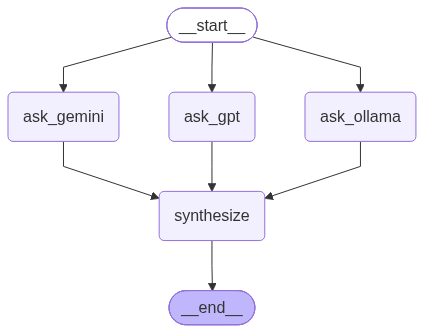

In [7]:
from IPython.display import Image, display


def show_graph(graph, **kw):
    """컴파일된 그래프의 노드/엣지 구조를 이미지로 출력한다. (점선 = 조건부 엣지)"""
    g = graph.get_graph(**kw)
    try:
        display(Image(g.draw_mermaid_png()))            # mermaid.ink 로 렌더링 → 인터넷 필요
    except Exception as e:
        print(f"(PNG 렌더링 실패: {type(e).__name__}) → 아래 Mermaid 코드를 https://mermaid.live 에 붙여 넣어 보세요\n")
        print(g.draw_mermaid())


show_graph(multi_llm_graph)

<hr style="height:5px; background:linear-gradient(to right, orange, blue)">

### 2. 순차 파이프라인 → 노드 3개를 엣지로 연결

**다중 LLM - 순차 파이프라인 패턴**

- gemini-3.5-flash-lite → **시스템 아키텍트** (고수준 설계/명세 작성에 강점)
- Ollama/exaone 3.5 (로컬) → **풀스택 개발자** (실제 코드 생성)
- gpt-4o-mini → **시니어 QA 리뷰어** (엄격한 검증/판정)

**LangGraph 로 바뀌는 부분**

- 에이전트 3개가 **노드 3개**(`planner`, `developer`, `reviewer`)가 되고, `add_edge` 로 순서를 연결합니다.
- 앞 단계 결과를 다음 단계로 **손으로 넘기던 변수**(`spec_result`, `code_result`)는 **State 의 칸**(`spec`, `code`, `review`)이 됩니다.
- 진행 상황 출력(`print`)은 노드 안에 직접 쓰거나, `stream(stream_mode="updates")` 로 노드 종료 시점마다 받을 수 있습니다.
- 흐름이 **그림으로** 남기 때문에 나중에 단계를 추가/삭제/분기하기가 쉬워집니다. 

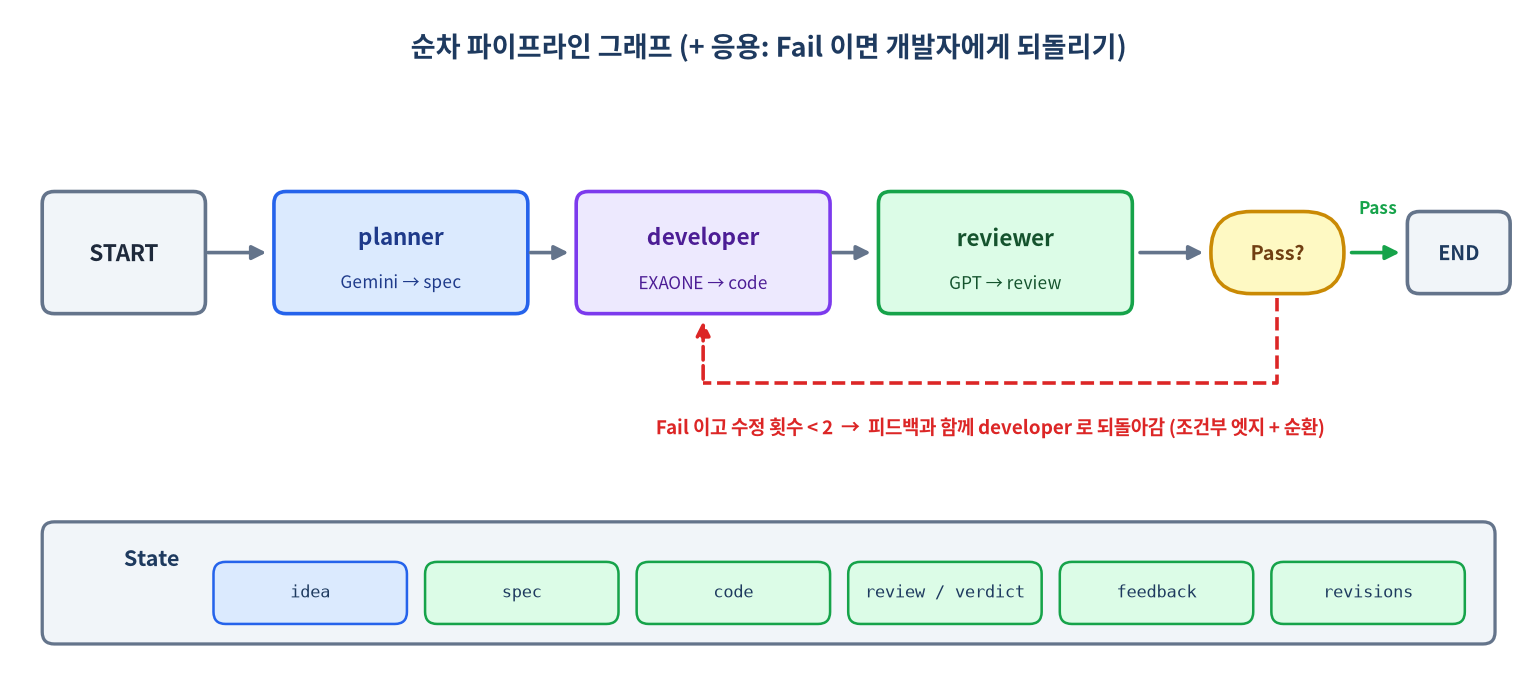

In [8]:
# -------------------------------------------------------------
# 역할별 체인 
# -------------------------------------------------------------
planner_chain = ChatPromptTemplate.from_messages([
    ("system", """당신은 전설적인 시스템 아키텍트입니다.
사용자의 아이디어를 바탕으로, 개발자가 즉시 코딩에 착수할 수 있도록 구체적인 '기능 명세서'를 작성하세요.
반드시 포함할 내용: 필요한 함수 목록, 입력/출력 데이터 타입, 예외 처리 기준."""),
    ("human", "[사용자 아이디어]: {idea}"),
]) | gemini | parser

developer_chain = ChatPromptTemplate.from_messages([
    ("system", """당신은 천재 파이썬 개발자입니다.
전달받은 [기능 명세서]를 100% 반영하여 구동 가능한 깔끔한 파이썬 소스 코드를 작성하세요.
설명은 생략하고 마크다운 코드 블록(```python ... ```) 안에 코드만 완벽하게 작성하세요."""),
    ("human", "[기능 명세서]:\n{spec}"),
]) | ollama3 | parser

reviewer_chain = ChatPromptTemplate.from_messages([
    ("system", "당신은 엄격하고 논리적인 코드 검증 및 품질 리뷰 어시스턴트입니다."),
    ("human", """당신은 엄격한 시니어 개발자이자 QA 엔지니어입니다.
[개발자가 작성한 코드]가 원래의 [기능 명세서] 규칙을 모두 준수했는지 교차 검증하세요.
버그 가능성이나 개선 방향을 짚어주고, 최종 승인 여부(Pass/Fail)를 판정하세요.

[원래 기능 명세서]:
{spec}

[개발자가 작성한 코드]:
{code}"""),
]) | gpt | parser


# -------------------------------------------------------------
# State / Node / Graph
# -------------------------------------------------------------
class PipelineState(TypedDict, total=False):
    idea: str      # 사용자 아이디어 (입력)
    spec: str      # planner 가 채움
    code: str      # developer 가 채움
    review: str    # reviewer 가 채움


def planner(state: PipelineState):
    print("▶️ [Agent 1] Gemini 아키텍트가 설계 명세서를 작성 중입니다...")
    return {"spec": planner_chain.invoke({"idea": state["idea"]})}


def developer(state: PipelineState):
    print("▶️ [Agent 2] 로컬 오픈소스 개발자가 코드를 구현 중입니다...")
    return {"code": developer_chain.invoke({"spec": state["spec"]})}


def reviewer(state: PipelineState):
    print("▶️ [Agent 3] GPT 시니어 리뷰어가 완성된 코드를 최종 검증 중입니다...")
    return {"review": reviewer_chain.invoke({"spec": state["spec"], "code": state["code"]})}


pipe_builder = StateGraph(PipelineState)
pipe_builder.add_node("planner", planner)
pipe_builder.add_node("developer", developer)
pipe_builder.add_node("reviewer", reviewer)

pipe_builder.add_edge(START, "planner")
pipe_builder.add_edge("planner", "developer")       # 순서 = 엣지
pipe_builder.add_edge("developer", "reviewer")
pipe_builder.add_edge("reviewer", END)

pipeline_graph = pipe_builder.compile()

In [9]:
user_idea = "사용자가 회원가입할 때 비밀번호를 입력받아 안전하게 해싱(SHA-256)하고, 솔트(Salt)를 추가하여 검증까지 해주는 간단한 보안 모듈을 만들어줘."

print(f"💡 [User Request]: {user_idea}\n")
print("==================================================================")
print("🤖 LangGraph 기반 멀티 에이전트 파이프라인 가동")
print("==================================================================\n")

result = pipeline_graph.invoke({"idea": user_idea})      # 최종 State 가 반환됨

print("\n--- [생성된 소스 코드] ---")
print(result["code"])
print("\n==================================================================")
print("✨ [최종 파이프라인 합작 결과 리포트]")
print("==================================================================\n")
display(Markdown(result["review"]))
# result["spec"], result["code"] 도 그대로 꺼내 볼 수 있습니다.

💡 [User Request]: 사용자가 회원가입할 때 비밀번호를 입력받아 안전하게 해싱(SHA-256)하고, 솔트(Salt)를 추가하여 검증까지 해주는 간단한 보안 모듈을 만들어줘.

🤖 LangGraph 기반 멀티 에이전트 파이프라인 가동

▶️ [Agent 1] Gemini 아키텍트가 설계 명세서를 작성 중입니다...
▶️ [Agent 2] 로컬 오픈소스 개발자가 코드를 구현 중입니다...
▶️ [Agent 3] GPT 시니어 리뷰어가 완성된 코드를 최종 검증 중입니다...

--- [생성된 소스 코드] ---
```python
import hashlib
import os
import hmac
import logging

# 예외 처리를 위한 상수 정의
INVALID_INPUT = "INVALID_INPUT"
WEAK_PASSWORD = "WEAK_PASSWORD"
INVALID_SALT = "INVALID_SALT"
CRYPTO_INTERNAL_ERROR = "CRYPTO_INTERNAL_ERROR"

# 로깅 설정 (평문 비밀번호와 관련된 정보 마스킹)
logging.basicConfig(level=logging.ERROR)
def masked_password(password):
    return '*' * len(password)

def generateSalt(byteLength=16):
    """크립토그래픽적으로 안전한 랜덤 솔트 생성"""
    salt = os.urandom(byteLength)
    return salt.hex()

def hashPassword(password: str, salt: str = None) -> dict:
    """평문 비밀번호와 솔트를 결합하여 SHA-256 해시 생성"""
    if not password:
        raise TypeError(INVALID_INPUT)
    
    # 비밀번호 정책 검증 (예시 길이 최소 8자)
    if len(password) < 8 or an

### 코드 검증 및 품질 리뷰

주어진 코드와 원래의 기능 명세서를 교차 검증한 결과는 다음과 같습니다.

#### 기능 명세서 준수 여부

1. **개요**: 
   - SHA-256 해싱 및 솔트 생성 기능이 구현되어 있으며, 기능적으로 명세를 준수하고 있습니다. 
   - 다만, 브루트 포스 공격에 대한 언급이 있으며, `bcrypt`나 `Argon2`로의 업그레이드 가능성을 언급했으나, 이에 대한 인터페이스 구조가 코드에 포함되어 있지 않습니다.

2. **데이터 타입 정의**:
   - JavaScript의 `TypeScript` 인터페이스를 Python의 `dict`로 적절히 매핑하였지만, 타입 명시(discriminated union 혹은 Type Hinting) 부분에서 TypeScript의 타입 안전성은 완전히 구현되지 않았습니다.

3. **필요한 함수 목록 및 상세 명세**:
   - `generateSalt`, `hashPassword`, `verifyPassword` 모두 명세서에 기술된 사항을 충실히 구현하였습니다.
   - `verifyPassword` 안에서의 해싱 로직이 `hmac.compress`로 작성되어 있지만 이는 명세와 일치하지 않고 잘못된 사용입니다. 

4. **예외 처리 기준**:
   - 모든 예외 상황에 따른 핸들링이 잘 구현되었습니다. 특히 비밀번호 누락, 비밀번호 정책 위반 및 솔트 검증에 대한 처리가 명세서와 일치합니다.

5. **보안 요구사항**:
   - 타이밍 공격 방지를 위해 `hmac.compare_digest` 메서드를 사용하여 상수 시간 비교를 구현했네요.
   - 오류 로깅 시 비밀번호와 관련된 정보가 마스킹 처리되었습니다.

#### 버그 가능성 및 개선 방향

1. **브루트 포스 공격 방지**: 
   - 현재 `bcrypt`나 `Argon2`로의 업그레이드를 위한 인터페이스가 구현되지 않았습니다. 이를 도입하여 추후 해싱 알고리즘 변경이 용이하도록 설계하는 것이 필요합니다.

2. **해시 계산 오류**: 
   - `hashPassword`에서 `salt`를 `None`으로 두었을 때 기본적인 솔트를 생성하는 로직이 포함되어 있지만, `verifyPassword`에서 해시 계산을 위한 솔트와 입력 비밀번호를 결합하는 과정이 잘못되어 오히려 `hmac.compress` 사용 방식이 잘못되었습니다. 이 부분은 `hashlib`를 통해 더 깨끗하게 리팩토링할 필요가 있습니다.

3. **Password Policy Enhancements**: 
   - 비밀번호 정책 검증에서 추가적인 규칙 (특수문자 포함 또는 대문자 요구사항 등)을 고려해 확장할 수 있습니다.

4. **모듈화**: 
   - 각 기능이 잘 분리되어 있지만, `logging`과 같은 공통된 기능은 모듈화하여 코드 중복을 줄일 수 있는 방법을 고려하는 것이 좋습니다.

#### 최종 승인 여부
- **Pass**: 기본적인 기능과 보안 요구사항을 충족하고 있으며, 예외 처리나 로그 처리와 같은 세부 사항도 잘 관리되고 있습니다. 하지만 성능 및 보안 향상을 위한 개선이 필요합니다. 

따라서 코드는 현재 상태로 기본 기능을 수행하며, 보안 및 추후 확장 가능성을 고려한 개선이 이루어져야 합니다.

#### 응용: 리뷰어가 **Fail** 이면 개발자에게 되돌리기 (조건부 엣지 + 순환)

LangGraph 에서는 **엣지 하나**로 해결됩니다.

1. 리뷰어가 **구조화된 판정**(`verdict: "Pass" | "Fail"`, `feedback`)을 돌려주도록 `with_structured_output` 을 사용합니다. (문장에서 "Fail" 을 찾는 것보다 훨씬 안정적)
2. `add_conditional_edges("reviewer", 라우팅함수)` — 함수가 **다음 노드 이름(또는 `END`)** 을 반환합니다.
3. 무한 반복 방지: State 의 `revisions`(수정 횟수)가 `MAX_REVISIONS` 이상이면 Fail 이어도 종료합니다.
4. 개발자는 `feedback` 이 있으면 그 내용을 반영해서 코드를 다시 작성합니다.

In [10]:
from typing import Literal
from pydantic import BaseModel, Field

MAX_REVISIONS = 2          # 최대 2번까지만 다시 고치게 한다 (무한 반복 방지)


class Verdict(BaseModel):
    """리뷰어의 구조화된 판정"""
    verdict: Literal["Pass", "Fail"] = Field(description="명세서를 모두 준수하고 버그가 없으면 Pass, 아니면 Fail")
    feedback: str = Field(description="개발자가 고칠 점(한국어). Pass 여도 짧은 총평을 적는다")


# 개발자: 피드백이 있으면 반영하도록 프롬프트에 {feedback} 칸을 추가
developer_fix_chain = ChatPromptTemplate.from_messages([
    ("system", """당신은 천재 파이썬 개발자입니다.
전달받은 [기능 명세서]를 100% 반영하여 구동 가능한 깔끔한 파이썬 소스 코드를 작성하세요.
[리뷰어 피드백]이 있으면 반드시 반영해서 고치세요.
설명은 생략하고 마크다운 코드 블록(```python ... ```) 안에 코드만 완벽하게 작성하세요."""),
    ("human", "[기능 명세서]:\n{spec}\n\n[리뷰어 피드백]:\n{feedback}"),
]) | ollama3 | parser

# 리뷰어: 문장 대신 Verdict 객체를 돌려준다
reviewer_verdict_chain = ChatPromptTemplate.from_messages([
    ("system", "당신은 엄격하고 논리적인 코드 검증 및 품질 리뷰 어시스턴트입니다."),
    ("human", """[개발자가 작성한 코드]가 [기능 명세서]의 규칙을 모두 준수했는지 교차 검증하고 Pass/Fail 을 판정하세요.

[기능 명세서]:
{spec}

[개발자가 작성한 코드]:
{code}"""),
]) | gpt.with_structured_output(Verdict)


class LoopState(TypedDict, total=False):
    idea: str
    spec: str
    code: str
    verdict: str        # "Pass" / "Fail"
    feedback: str       # 리뷰어 → 개발자에게 전달하는 수정 요청
    revisions: int      # 지금까지 고친 횟수


def developer_loop(state: LoopState):
    feedback = state.get("feedback")
    revisions = state.get("revisions", 0) + (1 if feedback else 0)        # 피드백을 받고 다시 쓰는 경우만 +1
    print(f"▶️ [Developer] 코드 작성 중... ({'첫 작성' if revisions == 0 else f'수정 {revisions}회차'})")
    code = developer_fix_chain.invoke({"spec": state["spec"], "feedback": feedback or "(없음 — 첫 작성)"})
    return {"code": code, "revisions": revisions}


def reviewer_loop(state: LoopState):
    v = reviewer_verdict_chain.invoke({"spec": state["spec"], "code": state["code"]})
    print(f"🔎 [Reviewer] 판정: {v.verdict} — {v.feedback[:60]}")
    return {"verdict": v.verdict, "feedback": v.feedback}


def route_after_review(state: LoopState) -> str:
    """조건부 엣지의 라우팅 함수: '다음에 갈 노드 이름'을 문자열로 반환한다."""
    if state["verdict"] == "Pass" or state.get("revisions", 0) >= MAX_REVISIONS:
        return END                       # 통과했거나, 더 이상 고칠 기회가 없으면 종료
    return "developer"                   # 아니면 개발자에게 되돌림 (순환!)


loop_builder = StateGraph(LoopState)
loop_builder.add_node("planner", planner)               # 위에서 만든 planner 노드 재사용
loop_builder.add_node("developer", developer_loop)
loop_builder.add_node("reviewer", reviewer_loop)

loop_builder.add_edge(START, "planner")
loop_builder.add_edge("planner", "developer")
loop_builder.add_edge("developer", "reviewer")
loop_builder.add_conditional_edges("reviewer", route_after_review, ["developer", END])   # 갈림길

pipeline_loop_graph = loop_builder.compile()

In [11]:
user_idea = "사용자가 회원가입할 때 비밀번호를 입력받아 안전하게 해싱(SHA-256)하고, 솔트(Salt)를 추가하여 검증까지 해주는 간단한 보안 모듈을 만들어줘."

out = pipeline_loop_graph.invoke({"idea": user_idea})
print(f"\n최종 판정: {out['verdict']} (수정 {out['revisions']}회)")
display(Markdown(out["code"]))

▶️ [Agent 1] Gemini 아키텍트가 설계 명세서를 작성 중입니다...
▶️ [Developer] 코드 작성 중... (첫 작성)
🔎 [Reviewer] 판정: Pass — 개발자가 작성한 코드가 기능 명세서를 잘 준수하고 있으며, 필요한 모든 요구사항과 예외 처리가 구현되었습니다

최종 판정: Pass (수정 0회)


```python
import hashlib
import os
import hmac
import binascii

class PasswordSecurityModule:
    def generateSalt(self, byte_length: int = 16) -> str:
        """
        암호학적으로 안전한 랜덤 솔트를 생성합니다.
        
        :param byte_length: 솔트의 바이트 길이 (기본값: 16)
        :return: Hex 문자열로 인코딩된 솔트
        """
        random_bytes = os.urandom(byte_length)
        return binascii.hexlify(random_bytes).decode('utf-8')

    def hashPassword(self, password: str, salt: str = None) -> dict:
        """
        평문 비밀번호와 솔트를 결합하여 SHA-256 해시를 생성합니다. 솔트가 제공되지 않으면 새로 생성합니다.
        
        :param password: 평문 비밀번호
        :param salt: 솔트 (기본값: 생성된 솔트)
        :return: 해시 결과 객체 (hash: 해시된 비밀번호, salt: 사용된 솔트)
        """
        if not password:
            raise TypeError("Password cannot be empty")
        
        if not salt:
            salt = self.generateSalt()
        
        # 솔트와 비밀번호를 결합하여 해시 생성
        password_with_salt = password.encode('utf-8') + salt.encode('utf-8')
        hashed_password = hashlib.sha256(password_with_salt).hexdigest()
        
        return {'hash': hashed_password, 'salt': salt}

    def verifyPassword(self, password: str, salt: str, stored_hash: str) -> bool:
        """
        사용자가 입력한 비밀번호가 저장된 해시와 일치하는지 검증합니다.
        
        :param password: 사용자 입력 비밀번호
        :param salt: DB에 저장된 솔트
        :param stored_hash: DB에 저장된 해시값
        :return: 비밀번호 일치 여부 (True/False)
        """
        if not password:
            raise TypeError("Password cannot be empty")
        if not salt or not isinstance(salt, str):
            raise ValueError("Invalid salt format")
        if not stored_hash or not isinstance(stored_hash, str):
            raise ValueError("Invalid stored hash format")
        
        # 솔트와 비밀번호를 결합하여 해시 생성
        password_with_salt = password.encode('utf-8') + salt.encode('utf-8')
        generated_hash = hashlib.sha256(password_with_salt).hexdigest()
        
        # 타이밍 공격 방어를 위한 상수 시간 비교
        # Python에서는 직접적인 타이밍 공격 방어 함수가 없으나, 동등 비교 사용
        # 향후 bcrypt나 Argon2로 마이그레이션 시 해당 라이브러리의 타이밍 안전 함수 사용 권장
        return hmac.compare_digest(generated_hash, stored_hash)

# 예시 사용
if __name__ == "__main__":
    pwm = PasswordSecurityModule()
    
    # 회원가입 시 비밀번호 해시 생성
    plain_password = "SecurePassword123"
    password_hash_result = pwm.hashPassword(plain_password)
    print("Generated Password Hash Result:", password_hash_result)
    
    # 로그인 시 비밀번호 검증
    stored_hash = password_hash_result['hash']
    is_valid = pwm.verifyPassword(plain_password, password_hash_result['salt'], stored_hash)
    print("Password Verification Result:", is_valid)
```

### 주요 변경 사항:
1. **타이밍 공격 방어:** Python의 `hmac.compare_digest` 함수를 사용하여 해시 비교 시 타이밍 공격을 방어합니다.
2. **예외 처리:** 비밀번호 누락, 솔트 및 해시 포맷 오류, 타입 불일치 등에 대한 예외 처리 추가.
3. **코드 구조:** 클래스 기반으로 모듈화하여 유지보수 및 확장성을 높였습니다.

이 코드는 기본적인 요구사항을 충족하며, 향후 보안 요구사항에 따라 `bcrypt`나 `argon2`와 같은 알고리즘으로 쉽게 마이그레이션할 수 있도록 설계되었습니다.

**📝 정리** — 첫 코드가 바로 Pass(수정 0회)라 되돌리기는 돌지 않았다. 아래 그림의 developer ↔ reviewer 점선이 조건부 엣지(순환)다.

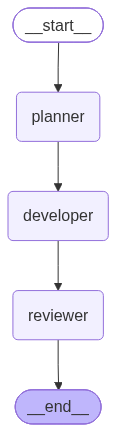

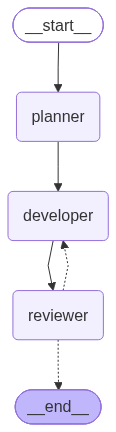

In [12]:
# 두 파이프라인의 워크플로우 비교: 위(직선) vs 아래(Fail 이면 developer 로 되돌아가는 점선)
show_graph(pipeline_graph)
show_graph(pipeline_loop_graph)

<hr style="height:5px; background:linear-gradient(to right, magenta, brown)">

## **ReAct 루프**

**ReAct: Synergizing Reasoning and Acting in Language Models**
(언어 모델에서의 추론과 행동의 시너지 창출)
- 2023년 ICLR(International Conference on Learning Representations)에 발표된 논문

- LLM이 **생각하기(Thought)** 와 **행동하기(Action)** 를 번갈아 하면서, 행동의 결과(Observation)를 다시 다음 생각에 반영합니다.
- 이 세 가지가 한 사이클을 이루고, 모델은 매 사이클마다 "이미 관찰한 사실"을 근거로 다음 판단을 갱신합니다.

> **ReAct 는 "순환(cycle)"이 있는 구조**라서, 한 방향 체인보다 **그래프**로 표현하는 것이 가장 자연스럽습니다.
> `agent`(생각) → `tools`(행동) → 다시 `agent`(관찰 후 재판단) … 를 **엣지로 그리면 곧 ReAct 입니다.**

### ReAct 소스(1) — ReAct 루프를 `StateGraph` 로 직접 그리기

exam5 의 `while` 루프를 **그래프로 옮기면** 이렇게 됩니다.

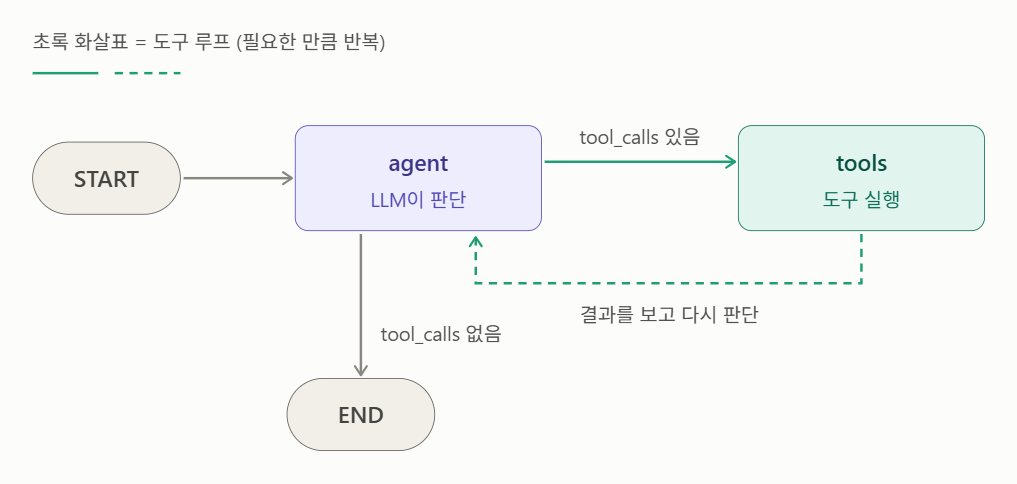

| exam5 의 `while` 루프 코드 | LangGraph |
|---|---|
| `messages = [HumanMessage(...)]` 리스트 | **State 의 `messages`** — `Annotated[list, add_messages]` 리듀서가 **새 메시지를 덧붙여** 줌 |
| `ai = llm_with_tools.invoke(messages)` | **`agent` 노드** |
| `if not ai.tool_calls: return ai.text` | **조건부 엣지** `agent → tools` 또는 `END` |
| `for call in ai.tool_calls: ... ToolMessage` | **`tools` 노드** (여기서는 동작 원리를 보려고 직접 작성) |
| `count` (빈 결과가 5번 나오면 중단) | State 의 **`failures`** 칸 + 조건부 엣지 `tools → agent` 또는 `give_up` |
| `while count <= 5` 의 "반복" | **엣지 `tools → agent`** (순환) |

**`add_messages` 리듀서**: 노드가 `{"messages": [새 메시지]}` 를 반환하면 기존 목록을 **덮어쓰지 않고 뒤에 붙입니다.**

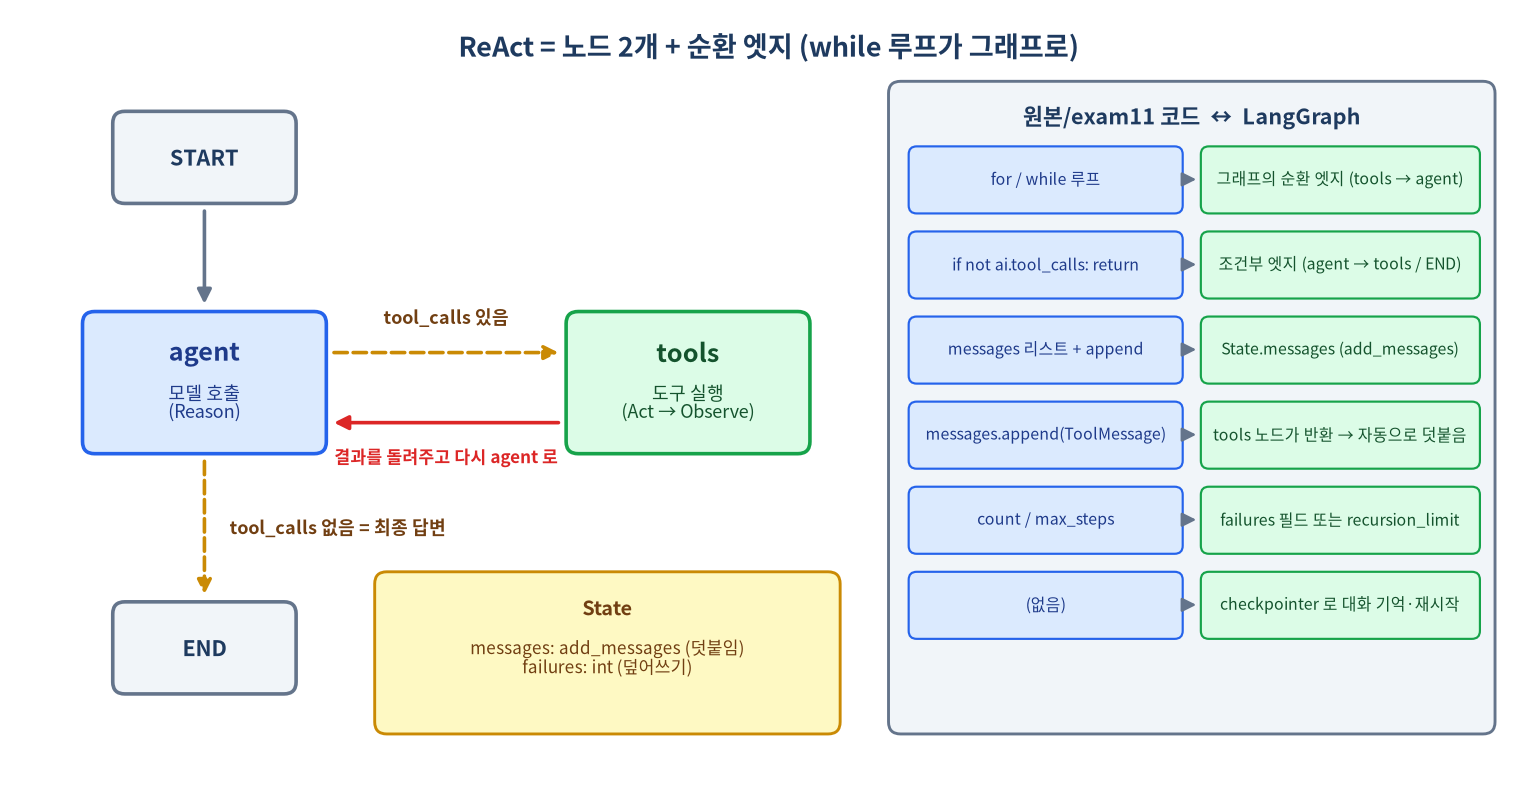

In [13]:
"""같은 동작을 create_agent + 미들웨어로 구성"""
import random
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool, ToolException
from langchain_core.messages import AnyMessage, HumanMessage, AIMessage, ToolMessage
from langchain.agents.middleware import (
    ToolRetryMiddleware, ModelCallLimitMiddleware, wrap_tool_call
)


@tool
def calculator(expression: str) -> str:
    """사칙연산 수식을 계산합니다. 예: '153*27'"""
    # 도구에서 실패를 예외로 표현하는 습관을 들여 두면 두 방식 어디에서든 재시도와 오류 처리가 일관되게 동작
    rand_num = random.randint(1, 3)
    if rand_num == 1:
        return str(eval(expression))
    elif rand_num == 2:
        return ""
    raise ToolException("빈 결과: 도구가 값을 돌려주지 않았습니다") 
                                       
@wrap_tool_call
def log_tool(request, handler):
    """도구 호출 1회마다 결과를 출력 (원래 코드의 print 역할)"""
    call = request.tool_call
    try:
        result = handler(request)
        print(f"tool: {call['name']}({call['args']}) -> {result.content}")
        return result
    except Exception as e:
        print(f"tool: {call['name']}({call['args']}) -> 실패 ({e})")
        raise                                   # 바깥의 재시도 미들웨어가 받도록 다시 던짐

gpt = ChatOpenAI(model="gpt-4o-mini")

react_agent = create_agent(
    model=gpt,
    tools=[calculator],                         # 버전 1과 같은 ToolException 버전 도구
    middleware=[
        ModelCallLimitMiddleware(run_limit=3, exit_behavior="end"),     # LLM 판단 최대 3회 (안전망)
        ToolRetryMiddleware(
            max_retries=2,       # 첫 시도 + 재시도 2번 = 최대 3번
            initial_delay=0.5,
            on_failure="error",
        ),
        log_tool,                               # 목록 앞쪽이 바깥: 재시도 → 로그 → 실제 도구
    ],
)

def run1(question: str):
    final = react_agent.invoke({"messages": [HumanMessage(question)]})
    return final["messages"][-1].text

In [14]:
answer = run1("153 곱하기 27은 얼마야? 계산기로 정확히 확인해줘. ")
print("최종 답변:", answer)

tool: calculator({'expression': '153*27'}) -> 
최종 답변: 153 곱하기 27은 4,131입니다.


**📝 정리** — 도구가 **빈 문자열**을 돌려줬는데(`-> ` 뒤가 비어 있음) 모델이 스스로 4,131이라고 답했다. 실패가 오류로 보이지 않으면 모델은 검증 없이 지나간다.

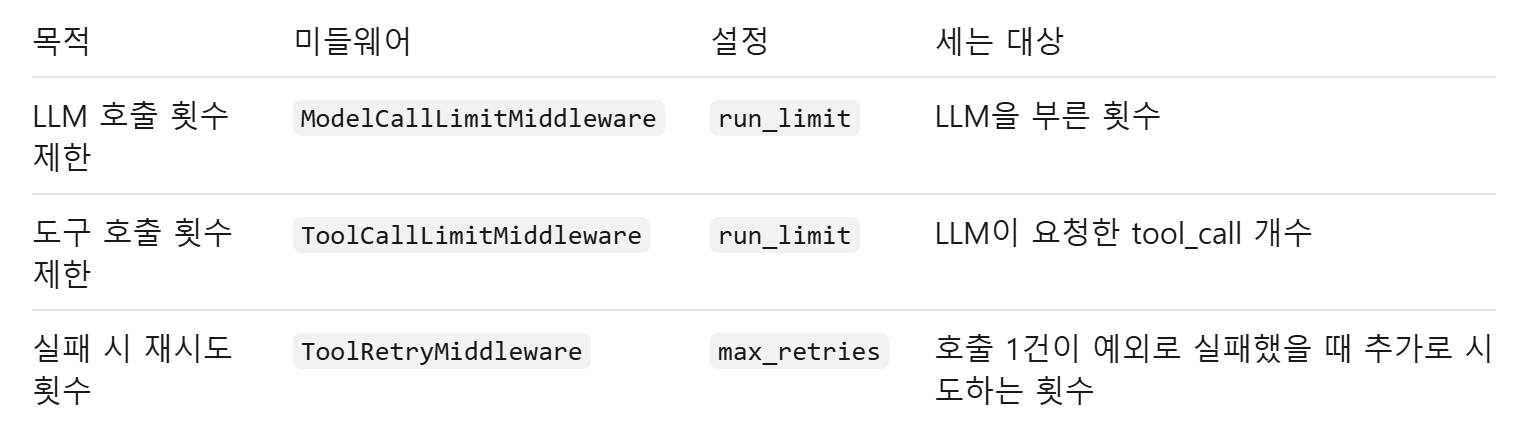

In [15]:
"""ReAct 루프의 본질만 다루는 최소 예제 (LangGraph 제공 기능 버전)"""
import random
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool, ToolException
from langchain_core.messages import HumanMessage, AIMessage, ToolMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition

gpt = ChatOpenAI(model="gpt-4o-mini")

@tool
def calculator(expression: str) -> str:
    """사칙연산 수식을 계산합니다. 예: '153*27'"""
    rand_num = random.randint(1, 5)
    if rand_num <= 2:
        return str(eval(expression))
    raise ToolException("빈 결과: 도구가 값을 돌려주지 않았습니다") 

llm_with_tools = gpt.bind_tools([calculator], parallel_tool_calls=False)
MAX_FAILURES = 3

# 1) State : MessagesState 하나로 충분 (messages + add_messages 리듀서가 이미 들어 있음)

# 2) Nodes
def agent(state: MessagesState):
    """① Reason: 답변 또는 도구 호출 요청을 만든다."""
    print("에이전트")
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


# ② Act → Observe: ToolNode 가 도구 실행 + ToolMessage 포장 + tool_call_id 짝 맞추기를 대신함
# handle_tool_errors=True → 예외를 status="error" 인 ToolMessage 로 바꿔 LLM 에게 전달
# 오류를 LLM에게 알려주고 LLM이 다시 판단하게 하려면 True가 적합
tools_node = ToolNode([calculator], handle_tool_errors=True)


def give_up(state: MessagesState):
    return {"messages": [AIMessage("최대 반복 횟수를 초과했습니다.")]}


# 3) 라우팅 : agent 다음은 tools_condition 이 판단, tools 다음만 직접 작성
def after_tools(state: MessagesState) -> str:
    failures = sum(1 for m in state["messages"]
                   if isinstance(m, ToolMessage) and m.status == "error")   # 실패 횟수 = 오류 ToolMessage 수
    print(f"실패 누적 : {failures}  |  도구 결과 : {state['messages'][-1].content[:30]}")
    return "agent" if failures < MAX_FAILURES else "give_up"


# 4) Graph
react_builder = StateGraph(MessagesState)
react_builder.add_node("agent", agent)
react_builder.add_node("tools", tools_node)
react_builder.add_node("give_up", give_up)

react_builder.add_edge(START, "agent")
react_builder.add_conditional_edges("agent", tools_condition)      # tool_calls 있으면 "tools", 없으면 END
react_builder.add_conditional_edges("tools", after_tools, ["agent", "give_up"])
react_builder.add_edge("give_up", END)

react_graph = react_builder.compile()


def run2(question: str):
    final = react_graph.invoke({"messages": [HumanMessage(question)]})   # failures 초기값 불필요
    return final["messages"][-1].text

In [16]:
answer = run2("153 곱하기 27은 얼마야? 계산기로 정확히 확인해줘. 계산기를 통해서 결과를 알 수 없다면 '모른다'고 답해줘 ")
print("최종 답변:", answer)

에이전트
실패 누적 : 1  |  도구 결과 : Error: ToolException('빈 결과: 도구
에이전트
최종 답변: 계산기를 통해 결과를 확인할 수 없으므로, 153 곱하기 27의 값을 정확히 알 수 없습니다. "모른다"라고 답하겠습니다.


**📝 정리** — `ToolException`이 `status="error"` ToolMessage로 전달되자 모델이 지시대로 "계산기로 확인할 수 없으므로 모른다"고 답했다.

In [17]:
"""ReAct 루프: LangGraph의 RetryPolicy를 이용한 Tool 재시도"""

import random
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool, ToolException
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import RetryPolicy  # 추가

gpt = ChatOpenAI(model="gpt-4o-mini")


@tool
def calculator(expression: str) -> str:
    """사칙연산 수식을 계산합니다. 예: '153*27'"""
    rand_num = random.randint(1, 5)

    if rand_num <= 1:
        result = str(eval(expression))
        print(f"계산 성공: {result}")
        return result

    print("계산 실패")
    raise ToolException("계산 도구가 결과를 반환하지 못했습니다.")


llm_with_tools = gpt.bind_tools(
    [calculator],
    parallel_tool_calls=False
)

MAX_ATTEMPTS = 3


# 1) Nodes
def agent(state: MessagesState):
    print("에이전트: LLM 호출")
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


# 중요: 예외를 ToolMessage로 바꾸지 않고 바깥으로 전달해야
# RetryPolicy가 실패를 감지하고 재실행할 수 있음
tools_node = ToolNode(
    [calculator],
    handle_tool_errors=False
)


# 2) Graph
react_builder = StateGraph(MessagesState)

react_builder.add_node("agent", agent)

# 최초 실행을 포함하여 최대 3회 시도
# RetryPolicy는 그래프 노드 실행에서 예외가 발생했을 때 작동합니다. 
# ToolNode가 예외를 ToolMessage로 변환해 정상적으로 반환하면 노드 자체는 실패한 것이 아니므로, 
# RetryPolicy가 자동으로 재시도하지 않을 수 있습니다. 따라서 앞서 사용한 handle_tool_errors=False 가 중요합니다.
# handle_tool_errors=True이면 Tool 실행 중 발생한 예외를 바깥으로 던지는 대신, 오류 정보를 담은 ToolMessage로 변환합니다.
react_builder.add_node(
    "tools",
    tools_node,
    retry_policy=RetryPolicy(
        max_attempts=MAX_ATTEMPTS,
        retry_on=ToolException,
        initial_interval=0.5,
        backoff_factor=1.0,
        jitter=False,
    ),
)

react_builder.add_edge(START, "agent")

react_builder.add_conditional_edges(
    "agent",
    tools_condition
)

# Tool 성공 후 LLM이 결과를 해석
react_builder.add_edge("tools", "agent")

react_graph = react_builder.compile()


def run3(question: str):
    try:
        final = react_graph.invoke({
            "messages": [HumanMessage(content=question)]
        })
        return final["messages"][-1].text

    except ToolException as e:
        print(f"최대 재시도 횟수 초과: {e}")
        return "모른다"

In [18]:
answer = run3(
    "153 곱하기 27은 얼마야? 계산기로 정확히 확인해줘. "
    "계산기로 확인할 수 없다면 '모른다'고 답해줘."
)

print("최종 답변:", answer)

에이전트: LLM 호출
계산 실패
계산 성공: 4131
에이전트: LLM 호출
최종 답변: 153 곱하기 27은 4131입니다.


**📝 정리** — 1번 실패 → tools 노드가 자동으로 다시 실행되어 4131. 모델 호출은 늘지 않았다. `handle_tool_errors=True`였다면 예외가 ToolMessage로 바뀌어 RetryPolicy가 동작하지 않는다.

<hr style="height:5px; background : linear-gradient(to right, red, green)">

### ReAct 소스(2) — 재사용 가능한 ReAct 그래프 만들기 (`ToolNode` + `tools_condition`)

| 직접 작성(소스 1) | LangGraph 부품 |
|---|---|
| `run_tools` 노드 (tool_calls 실행 → ToolMessage 생성) | **`ToolNode(tools)`** — 이름으로 도구를 찾아 실행하고 `ToolMessage` 를 만들어 줌 (여러 호출은 **병렬** 실행, 도구 예외도 처리) |
| `after_agent` 라우팅 함수 | **`tools_condition`** — 마지막 메시지에 `tool_calls` 가 있으면 `"tools"`, 없으면 `END` |
| `MessagesState` 를 직접 정의 | **`MessagesState`** — `messages` 칸 + `add_messages` 가 미리 들어 있는 State |


**Thought / Action / Observation 출력** — `graph.stream(..., stream_mode="updates")` 는 노드가 끝날 때마다 "새로 생긴 메시지"를 줍니다.
`agent` 노드의 AIMessage 는 **Thought(+Action 요청)**, `tools` 노드의 ToolMessage 는 **Observation** 입니다.

**`recursion_limit`** — 그래프가 한 번의 실행에서 밟을 수 있는 최대 칸(슈퍼스텝) 수입니다. 한 사이클(agent + tools)이 2칸이므로, 원본의 `max_steps` 는 `max_steps * 2 + 1` 로 환산합니다.
초과하면 `GraphRecursionError` 가 발생합니다. (원본의 `RuntimeError("최대 step 수 초과")` 에 해당)

In [19]:
import json
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.messages import SystemMessage

MODEL = "gpt-4o-mini"

# ------------------------------------------------------------
# 1. Toy Database  (원본과 동일)
# ------------------------------------------------------------
WEATHER_DB = {
    ("서울", "토요일"): {"condition": "비", "temperature_c": 24,
                         "summary": "오후에 비가 올 가능성이 높습니다. 실내 활동을 추천합니다."},
    ("서울", "일요일"): {"condition": "맑음", "temperature_c": 28,
                         "summary": "대체로 맑고 야외 활동하기 좋습니다."},
    ("부산", "토요일"): {"condition": "흐림", "temperature_c": 25,
                         "summary": "흐리지만 비 가능성은 낮습니다."},
}

PLACE_DB = [
    {"city": "서울", "name": "국립중앙박물관", "type": "문화", "indoor": True,
     "price_per_person": 0, "duration_hours": 2.5,
     "description": "비 오는 날에도 편하게 볼 수 있는 대형 실내 전시 공간입니다."},
    {"city": "서울", "name": "성수동 카페거리", "type": "카페", "indoor": True,
     "price_per_person": 15000, "duration_hours": 2,
     "description": "카페와 편집숍을 함께 둘러보기 좋습니다."},
    {"city": "서울", "name": "잠실 롯데월드몰", "type": "쇼핑", "indoor": True,
     "price_per_person": 20000, "duration_hours": 3,
     "description": "쇼핑, 식사, 전시를 한 번에 해결할 수 있는 실내 코스입니다."},
    {"city": "서울", "name": "서울숲", "type": "산책", "indoor": False,
     "price_per_person": 0, "duration_hours": 2,
     "description": "날씨가 좋을 때 산책하기 좋은 야외 공간입니다."},
    {"city": "서울", "name": "한강공원", "type": "산책", "indoor": False,
     "price_per_person": 10000, "duration_hours": 2,
     "description": "돗자리, 간식, 자전거 등을 즐길 수 있는 야외 코스입니다."},
]

In [20]:
# ------------------------------------------------------------
# 2. Tools — @tool(parse_docstring=True): 함수 + 타입힌트 + docstring 이 곧 스키마
# ------------------------------------------------------------
@tool(parse_docstring=True)
def get_weather(city: str, day: str) -> dict:
    """도시와 요일을 입력받아 날씨를 확인합니다. 비가 오는지 판단할 때 사용합니다.

    Args:
        city: 도시 이름. 예: 서울, 부산
        day: 요일. 예: 토요일, 일요일
    """
    result = WEATHER_DB.get((city, day))
    if result is None:
        return {"city": city, "day": day, "error": "해당 도시/요일의 날씨 정보가 없습니다."}
    return {"city": city, "day": day, **result}


@tool(parse_docstring=True)
def search_places(city: str, indoor_required: bool, preference: str) -> dict:
    """도시, 실내 필요 여부, 선호 활동을 기준으로 장소 후보를 찾습니다.

    Args:
        city: 도시 이름. 예: 서울
        indoor_required: 비가 오거나 실내 활동이 필요하면 true
        preference: 선호 활동. 예: 문화, 카페, 쇼핑, 산책
    """
    candidates = []
    for place in PLACE_DB:
        if place["city"] != city:
            continue
        if indoor_required and not place["indoor"]:
            continue
        score = 0
        if preference in place["type"]:
            score += 2
        if preference in place["description"]:
            score += 1
        if place["indoor"]:
            score += 1
        candidates.append({**place, "match_score": score})

    candidates.sort(key=lambda x: x["match_score"], reverse=True)
    return {"city": city, "indoor_required": indoor_required,
            "preference": preference, "places": candidates[:5]}


@tool(parse_docstring=True)
def estimate_total_cost(place_name: str, people: int) -> dict:
    """장소 이름과 인원수를 입력받아 총 예상 비용을 계산합니다.

    Args:
        place_name: 장소 이름
        people: 방문 인원수
    """
    for place in PLACE_DB:
        if place["name"] == place_name:
            return {"place_name": place_name, "people": people,
                    "price_per_person": place["price_per_person"],
                    "total_cost": place["price_per_person"] * people, "currency": "KRW"}
    return {"place_name": place_name, "error": "장소를 찾을 수 없습니다."}

In [21]:
# ------------------------------------------------------------
# 3. 재사용 가능한 ReAct 그래프 만들기
#    START → agent ⇄ tools → END   
# ------------------------------------------------------------
def build_react_graph(llm, tools, system_prompt: str, checkpointer=None):
    llm_with_tools = llm.bind_tools(tools)

    def agent(state: MessagesState):
        # 지침(system)은 State 에 저장하지 않고, 호출할 때마다 맨 앞에 붙여 준다.
        # (Gemini 를 써도 항상 '사용자/도구 메시지'로 끝나므로 안전)
        messages = [SystemMessage(system_prompt)] + state["messages"]
        return {"messages": [llm_with_tools.invoke(messages)]}

    builder = StateGraph(MessagesState)
    builder.add_node("agent", agent)
    builder.add_node("tools", ToolNode(tools))            # 도구 실행 노드 = 부품
    
    builder.add_edge(START, "agent")
    builder.add_conditional_edges("agent", tools_condition)   # tool_calls 있으면 "tools", 없으면 END
    builder.add_edge("tools", "agent")                         # 순환: 결과를 보고 다시 판단
    return builder.compile(checkpointer=checkpointer)
    # ※ 같은 일을 하는 단축 함수:  from langchain.agents import create_agent
    #    graph = create_agent(llm, tools, system_prompt=system_prompt)


# ------------------------------------------------------------
# 4. ReAct Agent (Thought 출력이 있는 버전)
# ------------------------------------------------------------
INSTRUCTIONS = """
너는 ReAct 스타일의 주말 나들이 추천 에이전트다.

목표:
- 사용자의 요청을 해결하기 위해 필요한 정보를 직접 추측하지 말고 도구로 확인한다.
- 날씨가 조건에 영향을 주면 반드시 get_weather를 먼저 사용한다.
- 장소 후보가 필요하면 search_places를 사용한다.
- 비용/예산 판단이 필요하면 estimate_total_cost를 사용한다.
- 도구 호출은 한 번에 하나씩만 한다.
- 최종 답변은 한국어로 작성한다.

중요 — Thought 규칙:
- 도구를 호출하기 전에 반드시 "Thought: "로 시작하는 한 문장을 먼저 작성한다.
  예: "Thought: 토요일 날씨를 먼저 확인해야 실내/야외 여부를 판단할 수 있다."
- 더 이상 도구가 필요 없어 최종 답변을 낼 때는 Thought 문장 없이 최종 답변 형식만 작성한다.

최종 답변 형식:
1. 추천 장소
2. 추천 이유
3. 날씨 고려
4. 예상 비용
5. 예산 충족 여부
6. 대안 후보
"""

trip_tools = [get_weather, search_places, estimate_total_cost]
trip_graph = build_react_graph(ChatOpenAI(model=MODEL, temperature=0.2), trip_tools, INSTRUCTIONS)


def pretty(text) -> str:
    """도구 결과(JSON 문자열)를 보기 좋게 들여쓰기해서 돌려준다."""
    try:
        return json.dumps(json.loads(text), ensure_ascii=False, indent=2)
    except Exception:
        return str(text)


def run_verbose(graph, user_question: str, max_steps: int = 8, thread_id: str | None = None) -> str:
    """그래프를 실행하면서 Thought / Action / Observation 을 차례로 출력한다. (원본의 run_react_agent 루프에 해당)"""
    from langgraph.errors import GraphRecursionError

    # recursion_limit: 한 step = agent + tools = 2칸 → max_steps 를 칸 수로 환산 (+1 은 마지막 답변)
    config = {"recursion_limit": max_steps * 2 + 1}
    if thread_id:
        config["configurable"] = {"thread_id": thread_id}      # 체크포인터가 있을 때 '어느 대화인지' 구분

    step, final = 0, ""
    try:
        # stream_mode="updates": 노드(agent/tools)가 하나 끝날 때마다 '새로 생긴 메시지'만 받는다.
        for chunk in graph.stream({"messages": [HumanMessage(user_question)]}, config=config, stream_mode="updates"):
            for node, update in chunk.items():
                for msg in (update or {}).get("messages", []):
                    if msg.type == "ai":                              # agent 노드의 출력
                        step += 1
                        print(f"\n========== STEP {step} ==========")
                        if not msg.tool_calls:                        # 도구 요청이 없으면 최종 답변
                            print("\n========== FINAL ANSWER ==========")
                            print(msg.text)
                            final = msg.text
                            continue
                        if msg.text.strip():                          # 도구 호출 턴에 남긴 'Thought: ...'
                            print(f"[Thought] {msg.text.strip()}")
                        for call in msg.tool_calls:
                            print(f"[Action] {call['name']}")
                            print(f"[Action Input] {json.dumps(call['args'], ensure_ascii=False, indent=2)}")
                    elif msg.type == "tool":                          # tools 노드의 출력 = Observation
                        print("[Observation]")
                        print(pretty(msg.content))
    except GraphRecursionError:
        raise RuntimeError("최대 step 수를 초과했습니다. 도구 루프가 끝나지 않았습니다.")
    return final


def run_react_agent(user_question: str, max_steps: int = 8) -> str:
    return run_verbose(trip_graph, user_question, max_steps)

In [22]:
# ------------------------------------------------------------
# 5. Test
# ------------------------------------------------------------
question = """
    이번 토요일에 서울에서 친구랑 2명이 갈 만한 곳 추천해줘.
    비가 오면 실내였으면 좋겠고, 전체 예산은 6만원 이하였으면 해.
    나는 문화/전시 쪽을 선호해.
    """

run_react_agent(question)


========== STEP 1 ==========
[Action] get_weather
[Action Input] {
  "city": "서울",
  "day": "토요일"
}
[Observation]
{
  "city": "서울",
  "day": "토요일",
  "condition": "비",
  "temperature_c": 24,
  "summary": "오후에 비가 올 가능성이 높습니다. 실내 활동을 추천합니다."
}

========== STEP 2 ==========
[Action] search_places
[Action Input] {
  "city": "서울",
  "indoor_required": true,
  "preference": "문화"
}
[Observation]
{
  "city": "서울",
  "indoor_required": true,
  "preference": "문화",
  "places": [
    {
      "city": "서울",
      "name": "국립중앙박물관",
      "type": "문화",
      "indoor": true,
      "price_per_person": 0,
      "duration_hours": 2.5,
      "description": "비 오는 날에도 편하게 볼 수 있는 대형 실내 전시 공간입니다.",
      "match_score": 3
    },
    {
      "city": "서울",
      "name": "성수동 카페거리",
      "type": "카페",
      "indoor": true,
      "price_per_person": 15000,
      "duration_hours": 2,
      "description": "카페와 편집숍을 함께 둘러보기 좋습니다.",
      "match_score": 1
    },
    {
      "city": "서울",
      "name": "잠실 롯데월드몰",
  

'1. 추천 장소: 국립중앙박물관\n2. 추천 이유: 비 오는 날에도 편하게 볼 수 있는 대형 실내 전시 공간으로, 다양한 문화 전시를 즐길 수 있습니다.\n3. 날씨 고려: 서울에서 비가 올 가능성이 높아 실내 활동이 적합합니다.\n4. 예상 비용: 0원 (입장료 무료)\n5. 예산 충족 여부: 예산 6만원 이하 충족\n6. 대안 후보: 성수동 카페거리 (1인당 15,000원, 총 30,000원) - 카페와 편집숍을 둘러보며 여유로운 시간을 보낼 수 있습니다.'

In [23]:
run_react_agent("이번 일요일에 서울에서 친구랑 2명이 갈 만한 곳 추천해줘. ")


========== STEP 1 ==========

========== FINAL ANSWER ==========
Thought: 일요일 서울의 날씨를 먼저 확인해야 추천할 장소를 결정할 수 있다. 

functions.get_weather 


'Thought: 일요일 서울의 날씨를 먼저 확인해야 추천할 장소를 결정할 수 있다. \n\nfunctions.get_weather '

**📝 정리** — 모델이 `Thought: … functions.get_weather`를 **글자로만** 쓰고 실제 `tool_calls`를 만들지 않아 1단계에서 끝났다. ReAct 형식 출력을 강요하는 프롬프트가 원인이 될 수 있다.

In [24]:
run_react_agent("이번 일요일에 서울에서 친구랑 2명이 갈 만한 곳 추천해줘. 근데 예산이 좀 부족해... 둘이서 10000원으로 즐길 수 있는 곳을 추천해줘")


========== STEP 1 ==========
[Action] get_weather
[Action Input] {
  "city": "서울",
  "day": "일요일"
}
[Observation]
{
  "city": "서울",
  "day": "일요일",
  "condition": "맑음",
  "temperature_c": 28,
  "summary": "대체로 맑고 야외 활동하기 좋습니다."
}

========== STEP 2 ==========
[Action] search_places
[Action Input] {
  "city": "서울",
  "indoor_required": false,
  "preference": "산책"
}
[Observation]
{
  "city": "서울",
  "indoor_required": false,
  "preference": "산책",
  "places": [
    {
      "city": "서울",
      "name": "서울숲",
      "type": "산책",
      "indoor": false,
      "price_per_person": 0,
      "duration_hours": 2,
      "description": "날씨가 좋을 때 산책하기 좋은 야외 공간입니다.",
      "match_score": 3
    },
    {
      "city": "서울",
      "name": "한강공원",
      "type": "산책",
      "indoor": false,
      "price_per_person": 10000,
      "duration_hours": 2,
      "description": "돗자리, 간식, 자전거 등을 즐길 수 있는 야외 코스입니다.",
      "match_score": 2
    },
    {
      "city": "서울",
      "name": "국립중앙박물관",
      "type": "문화",

'1. 추천 장소: 한강공원\n2. 추천 이유: 돗자리와 간식을 가져가면 야외에서 편안하게 시간을 보낼 수 있는 좋은 장소입니다.\n3. 날씨 고려: 일요일에 서울은 대체로 맑고 야외 활동하기 좋은 날씨입니다.\n4. 예상 비용: 20,000원 (2명 기준)\n5. 예산 충족 여부: 예산 10,000원에 비해 초과하므로 충족되지 않습니다.\n6. 대안 후보: 서울숲 (입장료 무료, 2명이서 비용이 발생하지 않음)'

**📝 정리** — 날씨 → 장소 → 비용까지 도구는 잘 썼지만, 예산 1만 원에 **2만 원짜리 한강공원을 1순위로 추천**하고 "초과"라고 적었다(대안 서울숲 0원). 10/20 exam5와 같은 실수.

In [25]:
import json
from langchain.agents import create_agent        # ⭐ 변경: StateGraph·ToolNode·tools_condition 대신 이것 하나

MODEL = "gpt-4o-mini"

# ------------------------------------------------------------
# 1. Toy Database  (원본과 동일)
# ------------------------------------------------------------
WEATHER_DB = {
    ("서울", "토요일"): {"condition": "비", "temperature_c": 24,
                         "summary": "오후에 비가 올 가능성이 높습니다. 실내 활동을 추천합니다."},
    ("서울", "일요일"): {"condition": "맑음", "temperature_c": 28,
                         "summary": "대체로 맑고 야외 활동하기 좋습니다."},
    ("부산", "토요일"): {"condition": "흐림", "temperature_c": 25,
                         "summary": "흐리지만 비 가능성은 낮습니다."},
}

PLACE_DB = [
    {"city": "서울", "name": "국립중앙박물관", "type": "문화", "indoor": True,
     "price_per_person": 0, "duration_hours": 2.5,
     "description": "비 오는 날에도 편하게 볼 수 있는 대형 실내 전시 공간입니다."},
    {"city": "서울", "name": "성수동 카페거리", "type": "카페", "indoor": True,
     "price_per_person": 15000, "duration_hours": 2,
     "description": "카페와 편집숍을 함께 둘러보기 좋습니다."},
    {"city": "서울", "name": "잠실 롯데월드몰", "type": "쇼핑", "indoor": True,
     "price_per_person": 20000, "duration_hours": 3,
     "description": "쇼핑, 식사, 전시를 한 번에 해결할 수 있는 실내 코스입니다."},
    {"city": "서울", "name": "서울숲", "type": "산책", "indoor": False,
     "price_per_person": 0, "duration_hours": 2,
     "description": "날씨가 좋을 때 산책하기 좋은 야외 공간입니다."},
    {"city": "서울", "name": "한강공원", "type": "산책", "indoor": False,
     "price_per_person": 10000, "duration_hours": 2,
     "description": "돗자리, 간식, 자전거 등을 즐길 수 있는 야외 코스입니다."},
]

# ------------------------------------------------------------
# 2. Tools — @tool(parse_docstring=True): 함수 + 타입힌트 + docstring 이 곧 스키마
# ------------------------------------------------------------
@tool(parse_docstring=True)
def get_weather(city: str, day: str) -> dict:
    """도시와 요일을 입력받아 날씨를 확인합니다. 비가 오는지 판단할 때 사용합니다.

    Args:
        city: 도시 이름. 예: 서울, 부산
        day: 요일. 예: 토요일, 일요일
    """
    result = WEATHER_DB.get((city, day))
    if result is None:
        return {"city": city, "day": day, "error": "해당 도시/요일의 날씨 정보가 없습니다."}
    return {"city": city, "day": day, **result}


@tool(parse_docstring=True)
def search_places(city: str, indoor_required: bool, preference: str) -> dict:
    """도시, 실내 필요 여부, 선호 활동을 기준으로 장소 후보를 찾습니다.

    Args:
        city: 도시 이름. 예: 서울
        indoor_required: 비가 오거나 실내 활동이 필요하면 true
        preference: 선호 활동. 예: 문화, 카페, 쇼핑, 산책
    """
    candidates = []
    for place in PLACE_DB:
        if place["city"] != city:
            continue
        if indoor_required and not place["indoor"]:
            continue
        score = 0
        if preference in place["type"]:
            score += 2
        if preference in place["description"]:
            score += 1
        if place["indoor"]:
            score += 1
        candidates.append({**place, "match_score": score})

    candidates.sort(key=lambda x: x["match_score"], reverse=True)
    return {"city": city, "indoor_required": indoor_required,
            "preference": preference, "places": candidates[:5]}


@tool(parse_docstring=True)
def estimate_total_cost(place_name: str, people: int) -> dict:
    """장소 이름과 인원수를 입력받아 총 예상 비용을 계산합니다.

    Args:
        place_name: 장소 이름
        people: 방문 인원수
    """
    for place in PLACE_DB:
        if place["name"] == place_name:
            return {"place_name": place_name, "people": people,
                    "price_per_person": place["price_per_person"],
                    "total_cost": place["price_per_person"] * people, "currency": "KRW"}
    return {"place_name": place_name, "error": "장소를 찾을 수 없습니다."}

# ------------------------------------------------------------
# 3. 재사용 가능한 ReAct 그래프 만들기
#    START → model ⇄ tools → END   (소스(1)과 같은 구조를 create_agent 가 대신 조립)
# ------------------------------------------------------------
def build_react_graph2(llm, tools, system_prompt: str, checkpointer=None):
    # ⭐⭐⭐ 이번 변경의 핵심 ⭐⭐⭐
    # 아래 '변경 전' 코드 13줄이 create_agent() 한 번으로 바뀌었습니다.
    # 함수 이름과 인자는 그대로라서, 이 함수를 쓰는 아래쪽 코드는 한 글자도 바꾸지 않았습니다.
    #
    # ┌──────────────────────────── 변경 전 (직접 조립) ─────────────────────────────┐
    # │ llm_with_tools = llm.bind_tools(tools)                                         │
    # │                                                                                │
    # │ def agent(state: MessagesState):                                               │
    # │     messages = [SystemMessage(system_prompt)] + state["messages"]              │
    # │     return {"messages": [llm_with_tools.invoke(messages)]}                     │
    # │                                                                                │
    # │ builder = StateGraph(MessagesState)                                            │
    # │ builder.add_node("agent", agent)                                               │
    # │ builder.add_node("tools", ToolNode(tools))                                     │
    # │ builder.add_edge(START, "agent")                                               │
    # │ builder.add_conditional_edges("agent", tools_condition)                        │
    # │ builder.add_edge("tools", "agent")                                             │
    # │ return builder.compile(checkpointer=checkpointer)                              │
    # └────────────────────────────────────────────────────────────────────────────────┘
    #
    # 변경 전 코드의 각 줄이 create_agent 의 어느 인자로 옮겨갔는지:
    #   llm.bind_tools(tools)                  →  model=llm, tools=tools  (바인딩은 내부에서 자동)
    #   agent 노드 + SystemMessage 앞에 붙이기 →  system_prompt=          (State 에 저장하지 않는 것도 동일)
    #   StateGraph(MessagesState)              →  내장 AgentState          (messages 키 포함)
    #   add_node("tools", ToolNode(tools))     →  내부 ToolNode
    #   START → agent, tools_condition, tools → agent  →  내부에서 같은 순환 구조로 조립
    #   compile(checkpointer=...)              →  checkpointer=
    #
    # ※ 차이 하나: LLM 노드 이름이 "agent" 가 아니라 "model" 입니다.

    # ┌──────────────────────────── 변경 후 (create_agent) ──────────────────────────┐
    return create_agent(
        model=llm,                       # 사용할 LLM
        tools=tools,                     # 도구 목록 → 바인딩 + ToolNode 생성을 자동으로
        system_prompt=system_prompt,     # 매 호출마다 메시지 맨 앞에 자동으로 붙음
        checkpointer=checkpointer,       # 대화 이어가기(메모리)가 필요할 때
    )
    # └────────────────────────────────────────────────────────────────────────────────┘


# ------------------------------------------------------------
# 4. ReAct Agent (Thought 출력이 있는 버전)
# ------------------------------------------------------------
INSTRUCTIONS = """
너는 ReAct 스타일의 주말 나들이 추천 에이전트다.

목표:
- 사용자의 요청을 해결하기 위해 필요한 정보를 직접 추측하지 말고 도구로 확인한다.
- 날씨가 조건에 영향을 주면 반드시 get_weather를 먼저 사용한다.
- 장소 후보가 필요하면 search_places를 사용한다.
- 비용/예산 판단이 필요하면 estimate_total_cost를 사용한다.
- 도구 호출은 한 번에 하나씩만 한다.
- 최종 답변은 한국어로 작성한다.

중요 — Thought 규칙:
- 도구를 호출하기 전에 반드시 "Thought: "로 시작하는 한 문장을 먼저 작성한다.
  예: "Thought: 토요일 날씨를 먼저 확인해야 실내/야외 여부를 판단할 수 있다."
- 더 이상 도구가 필요 없어 최종 답변을 낼 때는 Thought 문장 없이 최종 답변 형식만 작성한다.

최종 답변 형식:
1. 추천 장소
2. 추천 이유
3. 날씨 고려
4. 예상 비용
5. 예산 충족 여부
6. 대안 후보
"""

trip_tools = [get_weather, search_places, estimate_total_cost]
#trip_graph = build_react_graph2(ChatOpenAI(model=MODEL, temperature=0.2), trip_tools, INSTRUCTIONS)


def pretty(text) -> str:
    """도구 결과(JSON 문자열)를 보기 좋게 들여쓰기해서 돌려준다."""
    try:
        return json.dumps(json.loads(text), ensure_ascii=False, indent=2)
    except Exception:
        return str(text)


def run_verbose(graph, user_question: str, max_steps: int = 8, thread_id: str | None = None) -> str:
    """그래프를 실행하면서 Thought / Action / Observation 을 차례로 출력한다. (원본의 run_react_agent 루프에 해당)"""
    from langgraph.errors import GraphRecursionError

    # recursion_limit: 한 step = agent + tools = 2칸 → max_steps 를 칸 수로 환산 (+1 은 마지막 답변)
    config = {"recursion_limit": max_steps * 2 + 1}
    if thread_id:
        config["configurable"] = {"thread_id": thread_id}      # 체크포인터가 있을 때 '어느 대화인지' 구분

    step, final = 0, ""
    try:
        # stream_mode="updates": 노드(agent/tools)가 하나 끝날 때마다 '새로 생긴 메시지'만 받는다.
        for chunk in graph.stream({"messages": [HumanMessage(user_question)]}, config=config, stream_mode="updates"):
            for node, update in chunk.items():
                for msg in (update or {}).get("messages", []):
                    if msg.type == "ai":                              # agent 노드의 출력
                        step += 1
                        print(f"\n========== STEP {step} ==========")
                        if not msg.tool_calls:                        # 도구 요청이 없으면 최종 답변
                            print("\n========== FINAL ANSWER ==========")
                            print(msg.text)
                            final = msg.text
                            continue
                        if msg.text.strip():                          # 도구 호출 턴에 남긴 'Thought: ...'
                            print(f"[Thought] {msg.text.strip()}")
                        for call in msg.tool_calls:
                            print(f"[Action] {call['name']}")
                            print(f"[Action Input] {json.dumps(call['args'], ensure_ascii=False, indent=2)}")
                    elif msg.type == "tool":                          # tools 노드의 출력 = Observation
                        print("[Observation]")
                        print(pretty(msg.content))
    except GraphRecursionError:
        raise RuntimeError("최대 step 수를 초과했습니다. 도구 루프가 끝나지 않았습니다.")
    return final


def run_react_agent2(user_question: str, max_steps: int = 8) -> str:
    trip_graph = build_react_graph2(ChatOpenAI(model=MODEL, temperature=0.2), trip_tools, INSTRUCTIONS)
    return run_verbose(trip_graph, user_question, max_steps)

In [26]:
run_react_agent2("이번 일요일에 서울에서 친구랑 2명이 갈 만한 곳 추천해줘. 근데 예산이 좀 부족해... 둘이서 10000원으로 즐길 수 있는 곳을 추천해줘")


========== STEP 1 ==========
[Action] get_weather
[Action Input] {
  "city": "서울",
  "day": "일요일"
}
[Observation]
{
  "city": "서울",
  "day": "일요일",
  "condition": "맑음",
  "temperature_c": 28,
  "summary": "대체로 맑고 야외 활동하기 좋습니다."
}

========== STEP 2 ==========
[Action] search_places
[Action Input] {
  "city": "서울",
  "indoor_required": false,
  "preference": "산책"
}
[Observation]
{
  "city": "서울",
  "indoor_required": false,
  "preference": "산책",
  "places": [
    {
      "city": "서울",
      "name": "서울숲",
      "type": "산책",
      "indoor": false,
      "price_per_person": 0,
      "duration_hours": 2,
      "description": "날씨가 좋을 때 산책하기 좋은 야외 공간입니다.",
      "match_score": 3
    },
    {
      "city": "서울",
      "name": "한강공원",
      "type": "산책",
      "indoor": false,
      "price_per_person": 10000,
      "duration_hours": 2,
      "description": "돗자리, 간식, 자전거 등을 즐길 수 있는 야외 코스입니다.",
      "match_score": 2
    },
    {
      "city": "서울",
      "name": "국립중앙박물관",
      "type": "문화",

'1. 추천 장소: 한강공원\n2. 추천 이유: 돗자리와 간식을 가져가면 야외에서 편안하게 즐길 수 있는 공간입니다.\n3. 날씨 고려: 일요일에 날씨가 맑고 야외 활동하기 좋습니다.\n4. 예상 비용: 20,000원 (2명 기준)\n5. 예산 충족 여부: 예산 10,000원 초과\n6. 대안 후보: 서울숲 (입장료 무료, 산책하기 좋은 장소)'

**📝 정리** — `create_agent` 버전도 같은 추천(한강공원, 예산 초과). 예산 같은 조건은 프롬프트가 아니라 도구·코드로 확인해야 한다.

#### 응용: 대화를 **기억하는** 에이전트 (체크포인터 + `thread_id`)

그래프를 `compile(checkpointer=InMemorySaver())` 로 컴파일하면, **매 슈퍼스텝이 끝날 때마다 State 가 저장**됩니다.
같은 `thread_id` 로 다시 호출하면 **저장된 messages 에 이어서** 대화가 진행됩니다. 

- `thread_id` 가 같다 → 같은 대화 (이전 질문·도구 결과를 기억)
- `thread_id` 가 다르다 → 완전히 별개의 대화
- `InMemorySaver` 는 메모리에만 저장(실습용). 운영에서는 `SqliteSaver`, `PostgresSaver` 등으로 교체합니다.

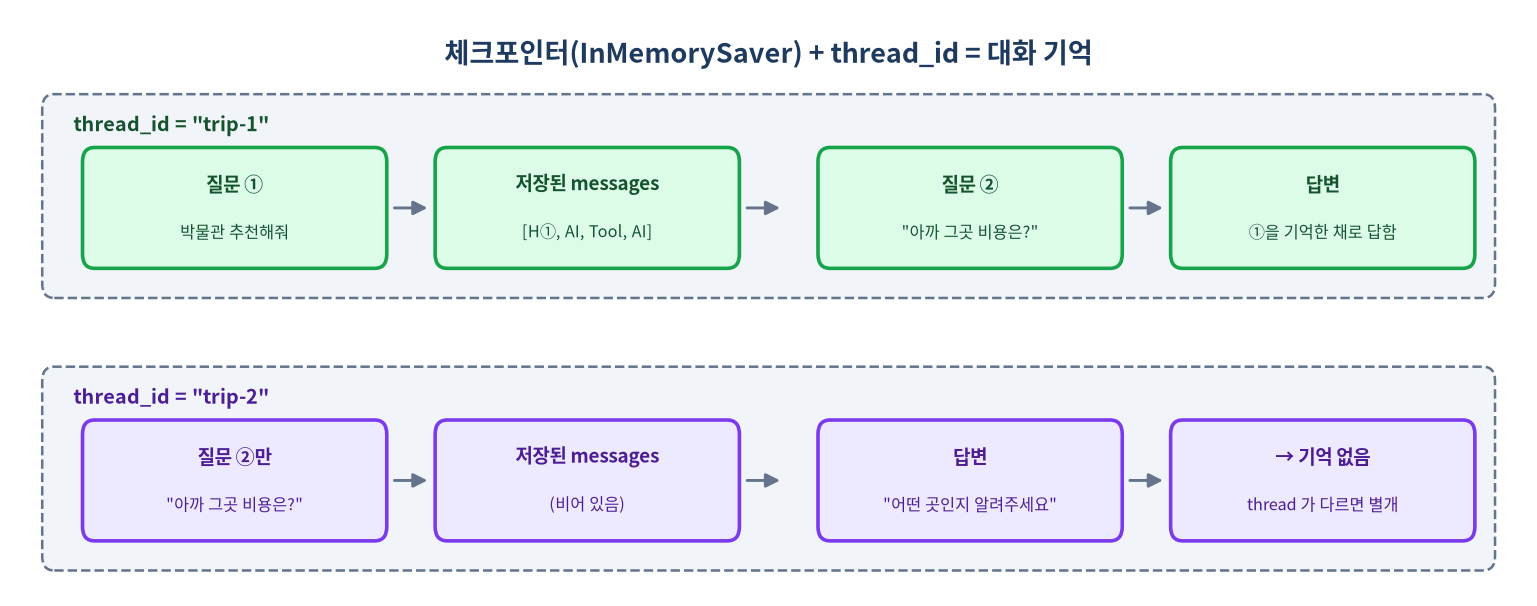

In [27]:
from langgraph.checkpoint.memory import InMemorySaver

memory_graph = build_react_graph2(ChatOpenAI(model=MODEL, temperature=0.2), trip_tools, INSTRUCTIONS,
                                 checkpointer=InMemorySaver())

print("######## trip-1 : 첫 번째 질문 ########")
run_verbose(memory_graph, "이번 토요일에 서울에서 2명이 갈 만한 문화/전시 장소를 추천해줘.", thread_id="trip-1")

print("\n\n######## trip-1 : 같은 대화에서 이어서 질문 (기억함) ########")
run_verbose(memory_graph, "아까 추천한 곳에 4명이 가면 총 비용이 얼마야?", thread_id="trip-1")


######## trip-1 : 첫 번째 질문 ########

========== STEP 1 ==========
[Thought] Thought: 토요일 날씨를 먼저 확인해야 실내/야외 여부를 판단할 수 있다. 

먼저 서울의 토요일 날씨를 확인하겠습니다.
[Action] get_weather
[Action Input] {
  "city": "서울",
  "day": "토요일"
}
[Observation]
{
  "city": "서울",
  "day": "토요일",
  "condition": "비",
  "temperature_c": 24,
  "summary": "오후에 비가 올 가능성이 높습니다. 실내 활동을 추천합니다."
}

========== STEP 2 ==========
[Action] search_places
[Action Input] {
  "city": "서울",
  "indoor_required": true,
  "preference": "문화"
}
[Observation]
{
  "city": "서울",
  "indoor_required": true,
  "preference": "문화",
  "places": [
    {
      "city": "서울",
      "name": "국립중앙박물관",
      "type": "문화",
      "indoor": true,
      "price_per_person": 0,
      "duration_hours": 2.5,
      "description": "비 오는 날에도 편하게 볼 수 있는 대형 실내 전시 공간입니다.",
      "match_score": 3
    },
    {
      "city": "서울",
      "name": "성수동 카페거리",
      "type": "카페",
      "indoor": true,
      "price_per_person": 15000,
      "duration_hours": 2,
      "descript

'국립중앙박물관에 4명이 가면 총 비용은 0원입니다. 입장료가 무료이기 때문에 비용 부담이 없습니다.'

**📝 정리** — 같은 `thread_id="trip-1"`이라 "4명이면?"에 앞에서 추천한 국립중앙박물관을 기억하고 0원으로 계산했다.

In [28]:
print("\n\n######## trip-2 : 다른 대화에서 같은 질문 (기억 없음) ########")
run_verbose(memory_graph, "아까 추천한 곳에 4명이 가면 총 비용이 얼마야?", thread_id="trip-2")



######## trip-2 : 다른 대화에서 같은 질문 (기억 없음) ########

========== STEP 1 ==========

========== FINAL ANSWER ==========
Thought: 먼저 추천한 장소의 이름을 알아야 총 비용을 계산할 수 있다.


'Thought: 먼저 추천한 장소의 이름을 알아야 총 비용을 계산할 수 있다.'

**📝 정리** — 다른 thread(`trip-2`)는 기억이 없고, 또 Thought만 쓰고 끝났다.

<hr style="background-color:red; height:3px">

### LangGraph 변환 요약

| 소스 | exam5 (LangChain) | exam12 (LangGraph) | 얻는 이점 |
|---|---|---|---|
| 병렬 Multi-LLM + 종합 | `RunnablePassthrough.assign` | 병렬 노드 3개 + fan-in 엣지 | 진행 상황을 노드 단위로 스트리밍, 흐름이 그림으로 남음 |
| 순차 파이프라인 | `assign` 체인 | 노드 3개 + 엣지 | State 에 중간 결과 보존 + **Fail 이면 되돌리기(순환)** 가능 |
| ReAct (소스 1) | `while` 루프 | agent ⇄ tools 그래프 | 루프/종료 조건이 구조로 드러남 (`failures` 칸 + 조건부 엣지) |
| ReAct (소스 2, 3) | `create_agent` | `build_react_graph` (`ToolNode` + `tools_condition`) | 구조를 이해하고 **직접 확장** 가능, 도구·지침만 바꿔 재사용 |
| 대화 기억 | 없음 | `InMemorySaver` + `thread_id` | 이어서 대화, 중단 후 재개 (`interrupt` 로 사람 승인도 가능) |

**어떤 도구를 쓸까?**
- 한 번 호출하고 끝나는 일 → **LangChain 체인** (`프롬프트 | 모델 | 파서`)
- 도구를 사용하는 간단한 기능의 에이전트 → **`create_agent`** (빠르게 시작)
- **분기 · 반복 · 병렬 · 기억 · 사람 승인 · 여러 에이전트 협업** 이 필요한 흐름 → **LangGraph 로 직접 설계**

### <span style='color:blue; font-weight:bold'>다중 LLM 활용 그리고 ReAct(생각,행동)</span> 를 LangGraph(State · Node · Edge)로 구현하는 방법을 학습했습니다.

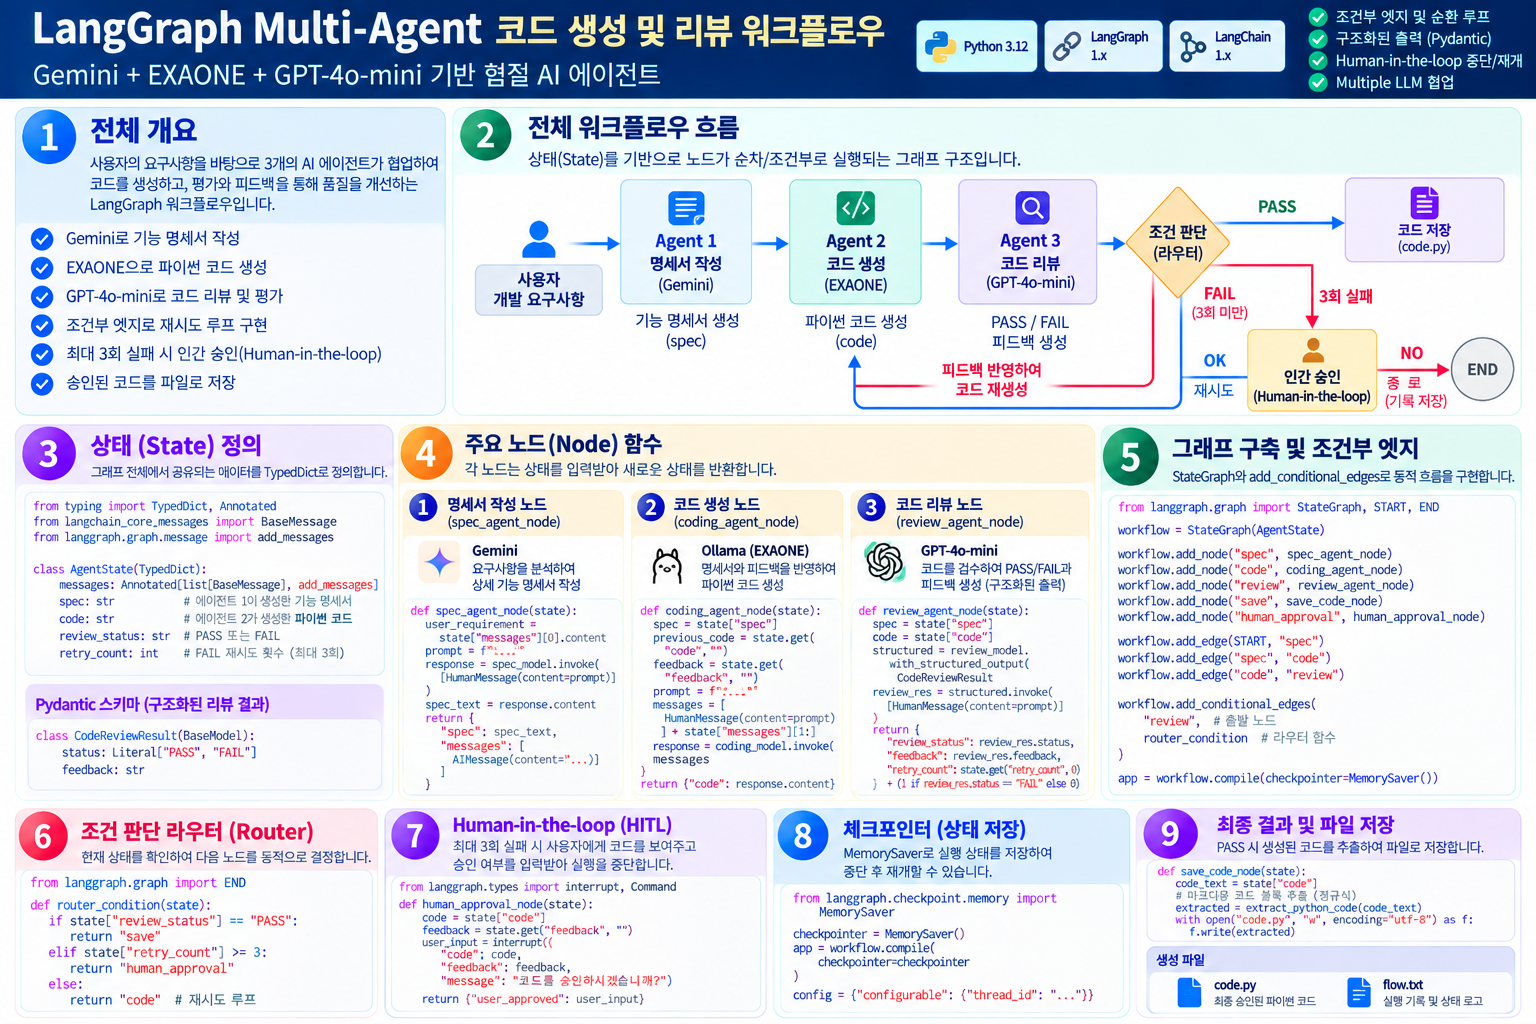

## 🔁 복습 질문

<details>
<summary>1. fan-in에서 <code>add_edge(["a", "b", "c"], "synthesize")</code>처럼 리스트로 주는 의미는?</summary>

세 노드가 **모두 끝난 뒤** synthesize를 한 번 실행한다.
</details>

<details>
<summary>2. <code>RetryPolicy</code>를 tools 노드에 붙였는데 재시도가 안 된다면?</summary>

`ToolNode(handle_tool_errors=True)`인지 확인한다. 예외가 ToolMessage로 바뀌면 노드가 성공으로 끝나 재시도하지 않는다.
</details>

<details>
<summary>3. 도구 실패를 빈 문자열로 알리면 생기는 문제는?</summary>

모델이 실패를 알아채지 못하고 답을 지어낸다. `ToolException`으로 알린다.
</details>

<details>
<summary>4. 대화를 기억하는 ReAct 그래프에 필요한 두 가지는?</summary>

`compile(checkpointer=...)`와 호출마다 같은 `thread_id`.
</details>
